# Tennis Dataset – Notebook

In [2]:
# =========================
# 1) Imports
# =========================
from pathlib import Path
from collections import Counter
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

ModuleNotFoundError: No module named 'scipy'

In [ ]:
# =========================
# 2) Data folder path
# =========================
# Change this to your data directory

DATA_DIR = Path(r"D:\TP\input")  # <-- Change this path as needed

if not DATA_DIR.exists():
    raise FileNotFoundError(f"DATA_DIR does not exist: {DATA_DIR}")
print("DATA_DIR =", DATA_DIR.resolve())


DATA_DIR = D:\TP\input


In [ ]:
# =========================
# 3) Load core CSV files (once)
# =========================
def find_csv(base: Path, candidates):
    """Case-insensitive search under base for one of the candidate filenames."""
    if isinstance(candidates, (str, Path)):
        candidates = [str(candidates)]
    lc = {str(c).lower() for c in candidates}
    for p in base.rglob("*.csv"):
        if p.name.lower() in lc:
            return p
    raise FileNotFoundError(f"None of these files found under {base}: {candidates}")

def pick_col(df: pd.DataFrame, candidates: list[str]) -> str | None:
    """Return the first matching column name (case-insensitive) from candidates, else None."""
    cols = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in cols:
            return cols[cand.lower()]
    return None


def load_csv(filename: str) -> tuple[Path, pd.DataFrame]:
    path = find_csv(DATA_DIR, filename)
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    return path, df

# Core tables used across questions
MatchHomeTeamInfo_path, MatchHomeTeamInfo = load_csv("MatchHomeTeamInfo.csv")
MatchAwayTeamInfo_path, MatchAwayTeamInfo = load_csv("MatchAwayTeamInfo.csv")
MatchEventInfo_path, MatchEventInfo       = load_csv("MatchEventInfo.csv")
PeriodInfo_path, PeriodInfo               = load_csv("PeriodInfo.csv")
MatchTimeInfo_path, MatchTimeInfo         = load_csv("MatchTimeInfo.csv")
MatchTournamentInfo_path, MatchTournamentInfo = load_csv("MatchTournamentInfo.csv")
MatchRoundInfo_path, MatchRoundInfo       = load_csv("MatchRoundInfo.csv")
GameInfo_path, GameInfo                 = load_csv("GameInfo.csv")

# Aliases expected by some questions
event_info   = MatchEventInfo
home_players = MatchHomeTeamInfo
away_players = MatchAwayTeamInfo

# Extra aliases for later questions
match_event_df = MatchEventInfo
match_home_df  = MatchHomeTeamInfo
match_away_df  = MatchAwayTeamInfo
game_info_df   = GameInfo

print("Loaded files:")
print(" -", MatchHomeTeamInfo_path.name)
print(" -", MatchAwayTeamInfo_path.name)
print(" -", MatchEventInfo_path.name)
print(" -", PeriodInfo_path.name)
print(" -", MatchTimeInfo_path.name)
print(" -", MatchTournamentInfo_path.name)
print(" -", MatchRoundInfo_path.name)
print(" -", GameInfo_path.name)

# -------------------------
# Optional tables (used by Extra Questions)
# -------------------------
def try_load_csv(filename: str):
    try:
        return load_csv(filename)
    except FileNotFoundError:
        return None, None

PowerInfo_path, PowerInfo = try_load_csv("PowerInfo.csv")
MatchVenueInfo_path, MatchVenueInfo = try_load_csv("MatchVenueInfo.csv")


Loaded files:
 - MatchHomeTeamInfo.csv
 - MatchAwayTeamInfo.csv
 - MatchEventInfo.csv
 - PeriodInfo.csv
 - MatchTimeInfo.csv
 - MatchTournamentInfo.csv
 - MatchRoundInfo.csv
 - GameInfo.csv


In [ ]:
# =========================
# 4) Shared plotting helper (used in Q16)
# =========================
def plot_green_bar(labels, values, title="", xlabel="", ylabel="", orientation="vertical", show_values=True, figsize=(10, 6)):
    """Simple bar plot helper (vertical/horizontal) with optional value labels."""
    labels = list(labels)
    values = np.asarray(values, dtype=float)

    plt.figure(figsize=figsize)
    ax = plt.gca()

    if orientation.lower().startswith("h"):
        bars = ax.barh(labels, values, color="#16A34A")
        ax.invert_yaxis()
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)

        if show_values:
            xpad = (values.max() - values.min()) * 0.01 if len(values) and values.max() != values.min() else 0.5
            for i, v in enumerate(values):
                ax.text(v + xpad, i, f"{v:.1f}", va="center", ha="left", fontsize=10)

        ax.grid(axis="x", linestyle="--", alpha=0.3)

    else:
        bars = ax.bar(labels, values, color="#16A34A")
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)

        if show_values:
            ypad = (values.max() - values.min()) * 0.01 if len(values) and values.max() != values.min() else 0.5
            for bar, v in zip(bars, values):
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + ypad, f"{v:.1f}",
                        ha="center", va="bottom", fontsize=10)

        ax.grid(axis="y", linestyle="--", alpha=0.3)

    ax.set_title(title, loc="left")
    plt.tight_layout()
    plt.show()


## QUESTION 1 : How many tennis players are included in the dataset?

In [ ]:
def unique_players_count(home_df: pd.DataFrame, away_df: pd.DataFrame):
    
    keep_cols = [
        "player_id", "name_code", "full_name", "country", "gender",
        "slug", "name"
    ]
    home = home_df[[c for c in keep_cols if c in home_df.columns]].copy()
    away = away_df[[c for c in keep_cols if c in away_df.columns]].copy()

    all_players = pd.concat([home, away], ignore_index=True)

    # 1) player_id
    if "player_id" in all_players.columns and all_players["player_id"].notna().any():
        unique = (
            all_players.dropna(subset=["player_id"])
            .drop_duplicates(subset=["player_id"])
        )
        key_used = "player_id"

    # 2) fallback: name_code
    elif "name_code" in all_players.columns and all_players["name_code"].notna().any():
        unique = (
            all_players.dropna(subset=["name_code"])
            .drop_duplicates(subset=["name_code"])
        )
        key_used = "name_code"

    # 3) fallback: mixed
    else:
        needed = [c for c in ["full_name", "country", "gender"] if c in all_players.columns]
        unique = (
            all_players.dropna(subset=["full_name"] if "full_name" in all_players.columns else needed)
            .drop_duplicates(subset=needed if needed else None)
        )
        key_used = "full_name(+country+gender)"

    return len(unique), key_used, unique

n_unique, key_used, unique_players_df = unique_players_count(MatchHomeTeamInfo, MatchAwayTeamInfo)
print(f"Unique players count: {n_unique} (distinct by: {key_used})")
# =========================
n_unique, key_used, unique_players_df = unique_players_count(MatchHomeTeamInfo, MatchAwayTeamInfo)

# show first 10 unique players
print(unique_players_df.head(10))


Unique players count: 2644 (distinct by: player_id)
    player_id name_code               full_name     country gender  \
0    287803.0       CAZ          Cazaux, Arthur      France      M   
1     62790.0       LES     Lestienne, Constant      France      M   
2     64580.0       COR            Ćorić, Borna     Croatia      M   
3    131442.0       MMO           Mmoh, Michael         USA      M   
4     22218.0       PAI           Paire, Benoit      France      M   
5    117916.0       SHA       Shapovalov, Denis      Canada      M   
6    264344.0       SHE   Shevchenko, Alexander  Kazakhstan      M   
8    248846.0       MAY           Mayot, Harold      France      M   
9    283070.0       RUN            Rune, Holger     Denmark      M   
13   192013.0       AUG  Auger-Aliassime, Felix      Canada      M   

                     slug                name  
0           cazaux-arthur           Cazaux A.  
1      lestienne-constant        Lestienne C.  
2             coric-borna        

## Question 2: What is the average height of the players?

Question 2: What is the average height of the players?
Unique players total: 2644
Players with valid height used in average: 1317 (dropped/invalid: 0)
Average height: 182.14 cm


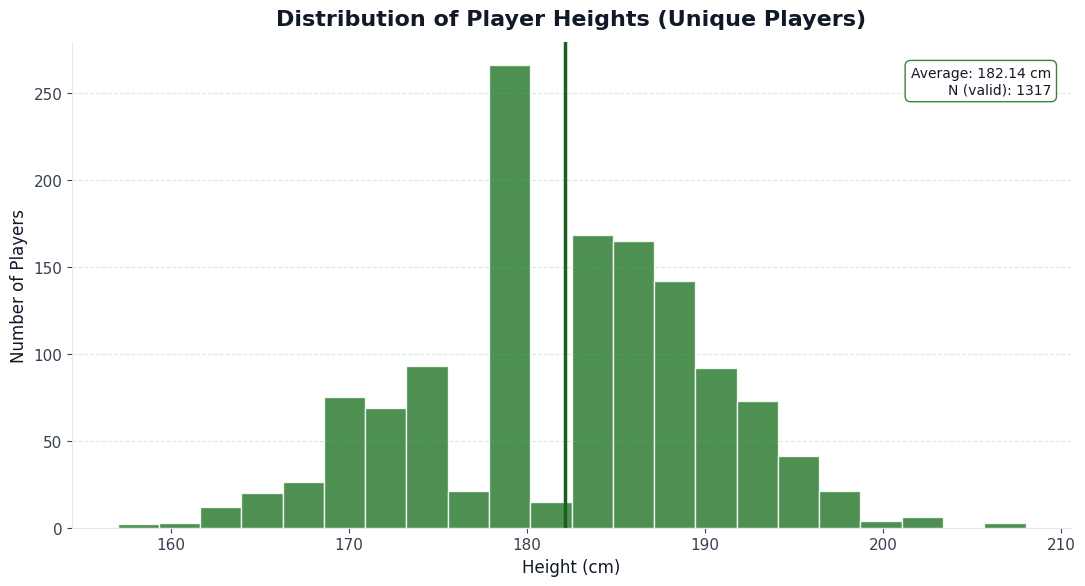

In [ ]:
# =========================
# Q2) Average height of players 
# =========================

def build_unique_players(home_df: pd.DataFrame, away_df: pd.DataFrame) -> pd.DataFrame:
    keep_cols = ["player_id", "name_code", "full_name", "country", "gender", "height"]
    home = home_df[[c for c in keep_cols if c in home_df.columns]].copy()
    away = away_df[[c for c in keep_cols if c in away_df.columns]].copy()

    allp = pd.concat([home, away], ignore_index=True)

    # Ensure numeric height
    if "height" not in allp.columns:
        raise ValueError("Column 'height' not found in the provided DataFrames.")
    allp["height"] = pd.to_numeric(allp["height"], errors="coerce")

    # Build a robust unique key (same logic you wanted)
    # 1) player_id
    key = pd.Series(np.nan, index=allp.index, dtype="object")

    if "player_id" in allp.columns:
        key = allp["player_id"].where(allp["player_id"].notna(), np.nan).astype("object")

    # 2) name_code fallback
    if "name_code" in allp.columns:
        key = key.where(key.notna(), allp["name_code"].where(allp["name_code"].notna(), np.nan).astype("object"))

    # 3) full_name + country + gender fallback
    fn = allp["full_name"] if "full_name" in allp.columns else pd.Series(np.nan, index=allp.index)
    co = allp["country"] if "country" in allp.columns else pd.Series("", index=allp.index)
    ge = allp["gender"] if "gender" in allp.columns else pd.Series("", index=allp.index)

    combo = (
        fn.astype("object").where(fn.notna(), np.nan)
    )
    combo = combo.astype("object")

    combo_fallback = (
        (fn.fillna("").astype(str).str.strip()) + " | " +
        (co.fillna("").astype(str).str.strip()) + " | " +
        (ge.fillna("").astype(str).str.strip())
    ).replace(" |  | ", np.nan)

    key = key.where(key.notna(), combo_fallback.astype("object"))

    allp["__unique_key__"] = key

    # Drop rows without any key
    allp = allp.dropna(subset=["__unique_key__"])

    # Deduplicate players (keep first occurrence)
    unique_players = allp.drop_duplicates(subset=["__unique_key__"]).copy()

    return unique_players


def normalize_height_to_cm(h: pd.Series) -> pd.Series:
    """Auto-detect meters vs cm and normalize to cm."""
    h_clean = h.dropna()
    if h_clean.empty:
        return h

    median = float(h_clean.median())

    # If median looks like meters (e.g., 1.75), convert to cm
    if 0.5 < median < 3.5:
        return h * 100.0

    # If already looks like cm (e.g., 175), keep
    return h


# --- Build unique players ---
unique_players_df = build_unique_players(MatchHomeTeamInfo, MatchAwayTeamInfo)

# --- Normalize heights to cm (safe auto-detection) ---
unique_players_df["height_cm"] = normalize_height_to_cm(unique_players_df["height"])

# --- Clean unrealistic heights (adjust if your dataset uses different scale) ---
before = unique_players_df["height_cm"].notna().sum()
heights = unique_players_df["height_cm"].copy()

# Typical human heights in cm: keep 100..250 to remove zeros/outliers
heights = heights.where((heights >= 100) & (heights <= 250), np.nan)
after = heights.notna().sum()

unique_players_df["height_cm_clean"] = heights

# --- Compute average ---
avg_height = float(unique_players_df["height_cm_clean"].mean())
count_used = int(unique_players_df["height_cm_clean"].notna().sum())
count_total = int(len(unique_players_df))

print("Question 2: What is the average height of the players?")
print(f"Unique players total: {count_total}")
print(f"Players with valid height used in average: {count_used} (dropped/invalid: {before - after})")
print(f"Average height: {avg_height:.2f} cm")

# =========================
# Chart (White & Green theme)
# =========================
vals = unique_players_df["height_cm_clean"].dropna().values

fig, ax = plt.subplots(figsize=(11, 6), facecolor="white")
ax.set_facecolor("white")

# Histogram
ax.hist(vals, bins=22, color="#2e7d32", alpha=0.85, edgecolor="white", linewidth=1)

# Mean line
ax.axvline(avg_height, color="#1b5e20", linewidth=2.5, linestyle="-")

# Labels & title
ax.set_title("Distribution of Player Heights (Unique Players)", pad=12)
ax.set_xlabel("Height (cm)")
ax.set_ylabel("Number of Players")

# Light green grid
ax.grid(axis="y", linestyle="--", alpha=0.25, color="#66bb6a")

# Remove extra borders for a cleaner look
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# Annotation
ax.text(
    0.98, 0.95,
    f"Average: {avg_height:.2f} cm\nN (valid): {count_used}",
    transform=ax.transAxes,
    ha="right", va="top",
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#2e7d32", alpha=0.95)
)

plt.tight_layout()
plt.show()


## Question 3: Which player has the highest number of wins?

3. Player with the highest number of wins: Popko, Dmitry (29 wins)


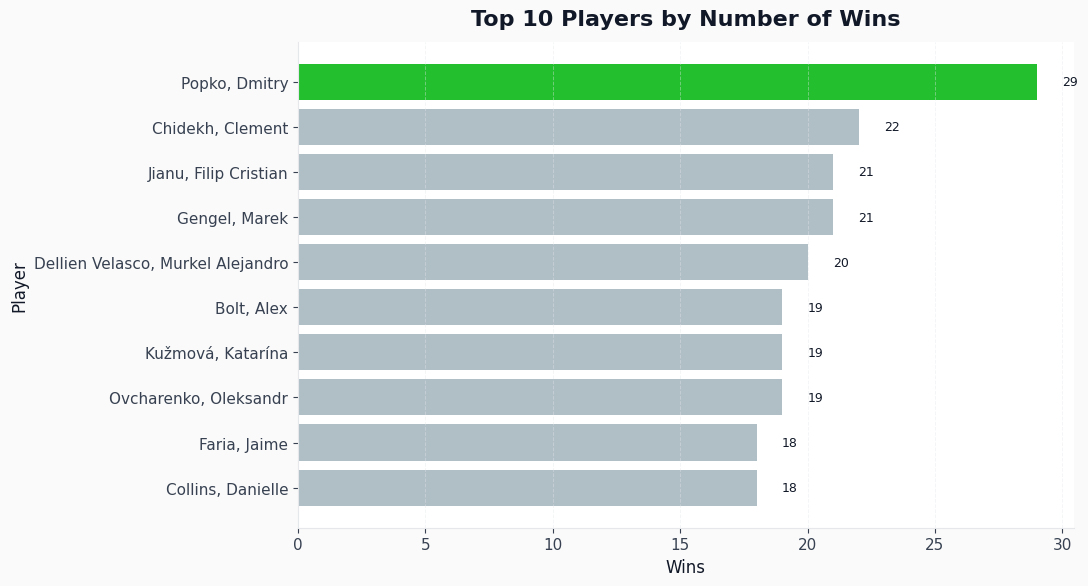

In [ ]:
# --- 3. Which player has the highest number of wins? ---


# Filter matches with a valid winner_code (1=Home, 2=Away)
match_results = (
    event_info.loc[event_info["winner_code"].isin([1, 2]), ["match_id", "winner_code"]]
    .dropna()
    .drop_duplicates(subset=["match_id"])
)

# Make sure each match_id maps to exactly one home/away player row
home_unique = (
    home_players[["match_id", "full_name"]]
    .dropna(subset=["match_id", "full_name"])
    .drop_duplicates(subset=["match_id"])
    .rename(columns={"full_name": "home_full_name"})
)

away_unique = (
    away_players[["match_id", "full_name"]]
    .dropna(subset=["match_id", "full_name"])
    .drop_duplicates(subset=["match_id"])
    .rename(columns={"full_name": "away_full_name"})
)

# Join and select the winner name based on winner_code
winners_df = (
    match_results.merge(home_unique, on="match_id", how="left")
    .merge(away_unique, on="match_id", how="left")
)

winners_df["winner_name"] = np.where(
    winners_df["winner_code"].eq(1),
    winners_df["home_full_name"],
    winners_df["away_full_name"],
)

winners_df = winners_df.dropna(subset=["winner_name"])

# Count wins
win_counts = winners_df["winner_name"].value_counts()

# Top winner(s) (handle ties)
top_wins = int(win_counts.max())
top_winners = win_counts[win_counts.eq(top_wins)].index.tolist()

if len(top_winners) == 1:
    print(f"3. Player with the highest number of wins: {top_winners[0]} ({top_wins} wins)")
else:
    print(f"3. Highest number of wins is {top_wins}, shared by: {', '.join(top_winners)}")

# Chart: Top 10 Players by Wins (swap X/Y via horizontal bars)

top10 = win_counts.head(10).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(11, 6), facecolor="#FAFAFA")
colors = ["#B0BEC5"] * len(top10)
colors[-1] = "#24bf2f"  
ax.set_facecolor("#FFFFFF")
ax.grid(axis="x", linestyle="--", alpha=0.25)           

ax.barh(top10.index, top10.values, color=colors)

ax.set_title("Top 10 Players by Number of Wins", pad=12)
ax.set_xlabel("Wins")
ax.set_ylabel("Player")

# Make it cleaner
ax.grid(axis="x", linestyle="--", linewidth=0.7, alpha=0.4)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# Value labels on bars
max_v = top10.values.max() if len(top10) else 0
offset = max(1, int(max_v * 0.01)) if max_v else 1
for i, v in enumerate(top10.values):
    ax.text(v + offset, i, str(int(v)), va="center", fontsize=9)

plt.tight_layout()
plt.show()


## QUESTION 4: What is the longest match recorded in terms of duration? (MatchTimeInfo)

In [ ]:
# Longest match duration (2-set and 3-set) using MatchTimeInfo.csv

# ---------------- CONFIG ----------------

FILENAME = "MatchTimeInfo.csv"

IQR_MULT = 3.0                 # 1.5 stricter, 3.0 looser (recommended start for "delay" outliers)
APPLY_TOTAL_IQR = True
APPLY_PERIOD_IQR = True
ENFORCE_EXACT_SET_COUNT = True # only matches with exactly 2 or exactly 3 positive periods
TOP_N = 10
# ----------------------------------------

def find_file_case_insensitive(base: Path, filename: str) -> Path:
    direct = base / filename
    if direct.exists():
        return direct

    # case-insensitive match anywhere under base
    target = filename.lower()
    for p in base.rglob("*.csv"):
        if p.name.lower() == target:
            return p

    raise FileNotFoundError(
        f"Could not find '{filename}' under: {base}\n"
        f"Make sure the file exists, or verify the directory is correct."
    )

def hhmmss(seconds: float) -> str:
    sec = int(round(float(seconds)))
    h = sec // 3600
    m = (sec % 3600) // 60
    s = sec % 60
    return f"{h:02d}:{m:02d}:{s:02d}"

def iqr_bounds(x: pd.Series, mult: float) -> tuple[float, float]:
    x = pd.to_numeric(x, errors="coerce").dropna()
    if x.empty:
        return (0.0, float("inf"))
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1
    lower = max(0.0, float(q1 - mult * iqr))
    upper = float(q3 + mult * iqr)
    if not np.isfinite(upper) or upper <= 0:
        upper = float("inf")
    return (lower, upper)

# ---------- LOAD ----------
path = MatchTimeInfo_path
print("Using MatchTimeInfo:", path)
df = MatchTimeInfo.copy()
df.columns = [c.strip() for c in df.columns]

if "match_id" not in df.columns:
    raise KeyError("Expected column 'match_id' in MatchTimeInfo.csv")

period_cols = [c for c in df.columns if re.fullmatch(r"period_\d+", c)]
if not period_cols:
    raise KeyError("No columns found like period_1, period_2, ... in MatchTimeInfo.csv")

period_cols = sorted(period_cols, key=lambda s: int(s.split("_")[1]))

for c in period_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# treat nonpositive as missing
df[period_cols] = df[period_cols].where(df[period_cols] > 0)

# number of positive periods = set_count
df["set_count"] = df[period_cols].notna().sum(axis=1).astype(int)

if ENFORCE_EXACT_SET_COUNT:
    df = df[df["set_count"].isin([2, 3])].copy()

df["total_seconds"] = df[period_cols].sum(axis=1, skipna=True)
df = df[df["total_seconds"].notna() & (df["total_seconds"] > 0)].copy()

# ---------- CLEAN OUTLIERS (separately for 2-set and 3-set) ----------
def clean_group(g: pd.DataFrame) -> pd.DataFrame:
    mask = pd.Series(True, index=g.index)

    if APPLY_TOTAL_IQR:
        lo, hi = iqr_bounds(g["total_seconds"], IQR_MULT)
        mask &= (g["total_seconds"] >= lo) & (g["total_seconds"] <= hi)

    if APPLY_PERIOD_IQR:
        k = int(g["set_count"].iloc[0])
        used_periods = period_cols[:k]
        for c in used_periods:
            lo, hi = iqr_bounds(g[c], IQR_MULT)
            mask &= g[c].notna() & (g[c] >= lo) & (g[c] <= hi)

    return g[mask].copy()

df_clean = (
    df.groupby("set_count", group_keys=False, sort=False)
      .apply(clean_group)
      .reset_index(drop=True)
)

print(f"Raw rows (2/3-set only): {len(df):,}")
print(f"Clean rows: {len(df_clean):,}  | removed: {len(df) - len(df_clean):,}")

# ---------- RESULTS ----------
def top_n(g: pd.DataFrame, n: int) -> pd.DataFrame:
    out = g.sort_values("total_seconds", ascending=False).head(n).copy()
    out["total_hhmmss"] = out["total_seconds"].apply(hhmmss)
    k = int(out["set_count"].iloc[0])
    for c in period_cols[:k]:
        out[c + "_hhmmss"] = out[c].apply(lambda v: hhmmss(v) if pd.notna(v) else None)

    front = ["match_id", "set_count", "total_seconds", "total_hhmmss"] + period_cols[:k] + [c + "_hhmmss" for c in period_cols[:k]]
    rest = [c for c in out.columns if c not in front]
    return out[front + rest]

top2 = top_n(df_clean[df_clean["set_count"] == 2], TOP_N) if (df_clean["set_count"] == 2).any() else pd.DataFrame()
top3 = top_n(df_clean[df_clean["set_count"] == 3], TOP_N) if (df_clean["set_count"] == 3).any() else pd.DataFrame()

print("\nLongest 2-set match:")
display(top2.head(1) if not top2.empty else "No 2-set matches after cleaning.")

print("\nLongest 3-set match:")
display(top3.head(1) if not top3.empty else "No 3-set matches after cleaning.")

print(f"\nTop {TOP_N} (2-set):")
display(top2 if not top2.empty else "No 2-set matches after cleaning.")

print(f"\nTop {TOP_N} (3-set):")
display(top3 if not top3.empty else "No 3-set matches after cleaning.")


Using MatchTimeInfo: D:\TP\input\MatchTimeInfo.csv
Raw rows (2/3-set only): 10,241
Clean rows: 10,068  | removed: 173

Longest 2-set match:


C:\Users\ASUS\AppData\Local\Temp\ipykernel_1608\843621563.py:99: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(clean_group)


,match_id,set_count,total_seconds,total_hhmmss,period_1,period_2,period_1_hhmmss,period_2_hhmmss,period_3,period_4,period_5,current_period_start_timestamp
9061,12177691,2,11006.0,03:03:26,4819.0,6187.0,01:20:19,01:43:07,NaN,NaN,NaN,1.711037e+09



Longest 3-set match:


,match_id,set_count,total_seconds,total_hhmmss,period_1,period_2,period_3,period_1_hhmmss,period_2_hhmmss,period_3_hhmmss,period_4,period_5,current_period_start_timestamp
2939,12201395,3,15929.0,04:25:29,5072.0,5010.0,5847.0,01:24:32,01:23:30,01:37:27,NaN,NaN,1.711704e+09



Top 10 (2-set):


,match_id,set_count,total_seconds,total_hhmmss,period_1,period_2,period_1_hhmmss,period_2_hhmmss,period_3,period_4,period_5,current_period_start_timestamp
9061,12177691,2,11006.0,03:03:26,4819.0,6187.0,01:20:19,01:43:07,NaN,NaN,NaN,1.711037e+09
4625,12066020,2,10949.0,03:02:29,4605.0,6344.0,01:16:45,01:45:44,NaN,NaN,NaN,1.707919e+09
8584,12170768,2,10873.0,03:01:13,5359.0,5514.0,01:29:19,01:31:54,NaN,NaN,NaN,1.710853e+09
6188,12110849,2,10807.0,03:00:07,4920.0,5887.0,01:22:00,01:38:07,NaN,NaN,NaN,1.709192e+09
8921,12174578,2,10730.0,02:58:50,4673.0,6057.0,01:17:53,01:40:57,NaN,NaN,NaN,1.710945e+09
7586,12151078,2,10641.0,02:57:21,5612.0,5029.0,01:33:32,01:23:49,NaN,NaN,NaN,1.710241e+09
8169,12159531,2,10637.0,02:57:17,4291.0,6346.0,01:11:31,01:45:46,NaN,NaN,NaN,1.711311e+09
7852,12154222,2,10495.0,02:54:55,5924.0,4571.0,01:38:44,01:16:11,NaN,NaN,NaN,1.710350e+09
7888,12154472,2,10358.0,02:52:38,4676.0,5682.0,01:17:56,01:34:42,NaN,NaN,NaN,1.710407e+09
8231,12160683,2,10273.0,02:51:13,5878.0,4395.0,01:37:58,01:13:15,NaN,NaN,NaN,1.710493e+09



Top 10 (3-set):


,match_id,set_count,total_seconds,total_hhmmss,period_1,period_2,period_3,period_1_hhmmss,period_2_hhmmss,period_3_hhmmss,period_4,period_5,current_period_start_timestamp
2939,12201395,3,15929.0,04:25:29,5072.0,5010.0,5847.0,01:24:32,01:23:30,01:37:27,NaN,NaN,1.711704e+09
2286,12163362,3,15505.0,04:18:25,5123.0,5119.0,5263.0,01:25:23,01:25:19,01:27:43,NaN,NaN,1.710524e+09
2820,12194966,3,15240.0,04:14:00,4958.0,4728.0,5554.0,01:22:38,01:18:48,01:32:34,NaN,NaN,1.711504e+09
2241,12159529,3,14737.0,04:05:37,3632.0,6387.0,4718.0,01:00:32,01:46:27,01:18:38,NaN,NaN,1.711317e+09
666,12064963,3,14708.0,04:05:08,4294.0,5062.0,5352.0,01:11:34,01:24:22,01:29:12,NaN,NaN,1.707910e+09
2597,12176348,3,14449.0,04:00:49,3833.0,5252.0,5364.0,01:03:53,01:27:32,01:29:24,NaN,NaN,1.711014e+09
2490,12172807,3,14095.0,03:54:55,3766.0,5629.0,4700.0,01:02:46,01:33:49,01:18:20,NaN,NaN,1.710958e+09
922,12082586,3,13923.0,03:52:03,3980.0,3476.0,6467.0,01:06:20,00:57:56,01:47:47,NaN,NaN,1.708435e+09
2016,12152339,3,13729.0,03:48:49,3360.0,4093.0,6276.0,00:56:00,01:08:13,01:44:36,NaN,NaN,1.710335e+09
2889,12197936,3,13678.0,03:47:58,3707.0,4433.0,5538.0,01:01:47,01:13:53,01:32:18,NaN,NaN,1.711551e+09


## QUESTION 5: How many sets are typically played in a tennis match?

In [ ]:
# Question 5

FILENAMES = {
    "matches": "MatchEventInfo.csv",
    "periods": "PeriodInfo.csv"
}

print("Loading required files...")
matches = MatchEventInfo
periods = PeriodInfo
format_col = matches['default_period_count'].dropna().astype(int)
counts = Counter(format_col)

total = len(format_col)

format_table = pd.DataFrame([
    {"Best of sets": n, "Matches": counts[n], "Percentage": (counts[n] / total) * 100}
    for n in sorted(counts)
])

print(f"Total matches analyzed: {total:,}\n")

print("Match format distribution:")
display(format_table)

unique_periods = sorted(periods['period'].unique())
print("\nUnique values in PeriodInfo 'period' column:", unique_periods)

print("\nConclusion:")
if len(counts) == 1 and 3 in counts:
    print(f"All {total:,} matches are configured as best-of-3 sets.")
    print("Typical professional tennis matches (ATP, WTA, most tournaments) use best-of-3.")
    print("Best-of-5 is reserved for men's singles in the four Grand Slams.")
    print("\nAnswer: 3 sets")
else:
    print("Mixed formats detected — review data.")


Loading required files...
Total matches analyzed: 16,873

Match format distribution:


,Best of sets,Matches,Percentage
0,3,16873,100.0



Unique values in PeriodInfo 'period' column: ['1ST', 'ALL']

Conclusion:
All 16,873 matches are configured as best-of-3 sets.
Typical professional tennis matches (ATP, WTA, most tournaments) use best-of-3.
Best-of-5 is reserved for men's singles in the four Grand Slams.

Answer: 3 sets


## QUESTION 6: Which country has produced the most successful tennis players?

In [ ]:
# Q6) Which country has produced the most successful tennis players?

# ---------------- CONFIG ----------------

TOP_RANK = 100 
MIN_OBSERVATIONS = 1    
SHOW_TOP_COUNTRIES = 20
SHOW_TOP_PLAYERS_PER_TOP_COUNTRY = 20
# ----------------------------------------

def mode_or_first(series: pd.Series):
    s = series.dropna()
    if s.empty:
        return np.nan
    m = s.mode()
    return m.iloc[0] if not m.empty else s.iloc[0]

# ---------- LOAD home/away ----------
home_path = MatchHomeTeamInfo_path
away_path = MatchAwayTeamInfo_path
home = MatchHomeTeamInfo.copy()
away = MatchAwayTeamInfo.copy()
home.columns = [c.strip() for c in home.columns]
away.columns = [c.strip() for c in away.columns]

# identifier + core fields
id_col_home = pick_col(home, ["player_id", "competitor_id", "team_id", "id", "player_num"])
id_col_away = pick_col(away, ["player_id", "competitor_id", "team_id", "id", "player_num"])
if not id_col_home or not id_col_away:
    raise KeyError("Could not find a player identifier column in Home/Away CSVs (expected player_id/competitor_id/team_id/id/player_num).")

country_col_home = pick_col(home, ["country"])
country_col_away = pick_col(away, ["country"])
if not country_col_home or not country_col_away:
    raise KeyError("Could not find 'country' column in Home/Away CSVs.")

rank_col_home = pick_col(home, ["current_rank", "rank"])
rank_col_away = pick_col(away, ["current_rank", "rank"])
if not rank_col_home or not rank_col_away:
    raise KeyError("Could not find 'current_rank' column in Home/Away CSVs.")

name_col_home = pick_col(home, ["full_name", "name"])
name_col_away = pick_col(away, ["full_name", "name"])

# normalize column names across home/away
home2 = home.rename(columns={
    id_col_home: "player_id",
    country_col_home: "country",
    rank_col_home: "current_rank",
    **({name_col_home: "player_name"} if name_col_home else {})
}).copy()

away2 = away.rename(columns={
    id_col_away: "player_id",
    country_col_away: "country",
    rank_col_away: "current_rank",
    **({name_col_away: "player_name"} if name_col_away else {})
}).copy()

home2["side"] = "HOME"
away2["side"] = "AWAY"

players_raw = pd.concat([home2, away2], ignore_index=True)

# basic cleaning
players_raw["player_id"] = pd.to_numeric(players_raw["player_id"], errors="coerce")
players_raw["current_rank"] = pd.to_numeric(players_raw["current_rank"], errors="coerce")

players_raw = players_raw.dropna(subset=["player_id", "country"]).copy()
players_raw["player_id"] = players_raw["player_id"].astype("int64")

# ranks: keep only positive
players_raw.loc[players_raw["current_rank"] <= 0, "current_rank"] = np.nan

print("Home:", home_path)
print("Away:", away_path)
print("Rows total (home+away):", len(players_raw))
print("Unique players:", players_raw["player_id"].nunique())
print("Rows with rank:", int(players_raw["current_rank"].notna().sum()))

# ---------- build player-level "success" ----------
# best_rank (minimum) per player; country/name as mode
player_dim = (
    players_raw
    .groupby("player_id", as_index=False)
    .agg(
        country=("country", mode_or_first),
        player_name=("player_name", mode_or_first) if "player_name" in players_raw.columns else ("country", lambda s: np.nan),
        best_rank=("current_rank", "min"),
        obs=("player_id", "size"),
        rank_obs=("current_rank", lambda s: int(pd.to_numeric(s, errors="coerce").notna().sum())),
    )
)

# keep players with enough observations
player_dim = player_dim[player_dim["obs"] >= MIN_OBSERVATIONS].copy()

# successful flag (you can change TOP_RANK)
player_dim["is_successful"] = player_dim["best_rank"].notna() & (player_dim["best_rank"] <= TOP_RANK)

# optional success score (higher is better)
# uses reciprocal rank so top ranks contribute more
player_dim["success_score"] = np.where(
    player_dim["best_rank"].notna(),
    1.0 / player_dim["best_rank"].astype(float),
    0.0
)

print("\nPlayers with any rank:", int(player_dim["best_rank"].notna().sum()))
print(f"Successful players (best_rank <= {TOP_RANK}):", int(player_dim["is_successful"].sum()))

# ---------- country-level result ----------
country_stats = (
    player_dim
    .groupby("country", as_index=False)
    .agg(
        successful_players=("is_successful", "sum"),
        players_with_rank=("best_rank", lambda s: int(pd.to_numeric(s, errors="coerce").notna().sum())),
        total_players=("player_id", "count"),
        best_rank_median=("best_rank", "median"),
        best_rank_min=("best_rank", "min"),
        success_score_sum=("success_score", "sum"),
    )
)

# rank countries primarily by number of successful players, then by score sum, then by median rank
country_stats = country_stats.sort_values(
    by=["successful_players", "success_score_sum", "best_rank_median"],
    ascending=[False, False, True]
).reset_index(drop=True)

winner = country_stats.head(1)

print("\nWinner country (by successful player count):")
display(winner)

print(f"\nTop {SHOW_TOP_COUNTRIES} countries:")
display(country_stats.head(SHOW_TOP_COUNTRIES))

# ---------- show top players from the top country ----------
top_country = winner.loc[0, "country"]
top_players = (
    player_dim[player_dim["country"] == top_country]
    .copy()
    .sort_values(by=["is_successful", "best_rank", "rank_obs", "obs"], ascending=[False, True, False, False])
)

print(f"\nTop players from {top_country} (best_rank / success):")
display(top_players.head(SHOW_TOP_PLAYERS_PER_TOP_COUNTRY))


Home: D:\TP\input\MatchHomeTeamInfo.csv
Away: D:\TP\input\MatchAwayTeamInfo.csv
Rows total (home+away): 24073
Unique players: 2644
Rows with rank: 23782

Players with any rank: 2584
Successful players (best_rank <= 100): 213

Winner country (by successful player count):


,country,successful_players,players_with_rank,total_players,best_rank_median,best_rank_min,success_score_sum
0,USA,26,222,225,651.0,3.0,1.789689



Top 20 countries:


,country,successful_players,players_with_rank,total_players,best_rank_median,best_rank_min,success_score_sum
0,USA,26,222,225,651.0,3.0,1.789689
1,Russia,19,136,137,584.0,4.0,1.304145
2,France,17,194,202,635.0,14.0,0.840343
3,Italy,13,202,205,839.5,2.0,1.136185
4,Spain,12,97,98,626.0,2.0,0.864760
5,Australia,12,92,92,563.0,9.0,0.484791
6,Argentina,11,98,98,660.0,19.0,0.438381
7,Germany,9,120,121,686.5,4.0,0.621053
8,Czech Republic,9,69,71,482.0,6.0,0.601046
9,China,9,61,63,683.0,7.0,0.385869



Top players from USA (best_rank / success):


,player_id,country,player_name,best_rank,obs,rank_obs,is_successful,success_score
1638,264983,USA,"Gauff, Cori",3.0,12,12,True,0.333333
152,44834,USA,"Pegula, Jessica",5.0,8,8,True,0.200000
730,136042,USA,"Fritz, Taylor",9.0,12,12,True,0.111111
93,35424,USA,"Keys, Madison",12.0,5,5,True,0.083333
741,138546,USA,"Paul, Tommy",14.0,15,15,True,0.071429
557,101101,USA,"Tiafoe, Frances",14.0,10,10,True,0.071429
302,58515,USA,"Collins, Danielle",15.0,23,23,True,0.066667
2292,385485,USA,"Shelton, Ben",15.0,11,11,True,0.066667
1180,207979,USA,"Navarro, Emma",20.0,16,16,True,0.050000
1037,195840,USA,"Korda, Sebastian",27.0,12,12,True,0.037037


## QUESTION 7:What is the average number of aces per match

QUESTION 7: What is the average number of aces per match?
Matches found (after filter): 11389
Matches used (valid numeric aces): 11389 | dropped: 0
Average aces per match: 5.31
Min: 0 | Median: 4 | Max: 52


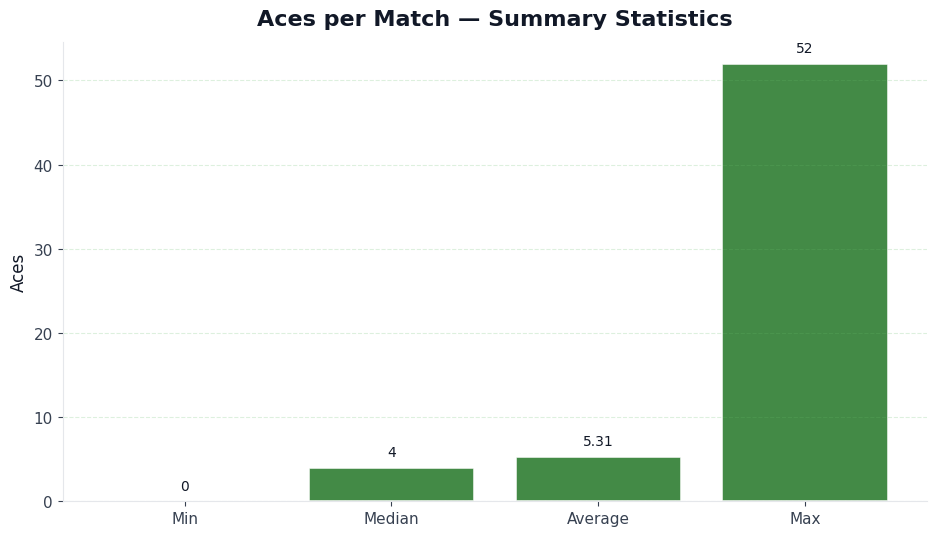

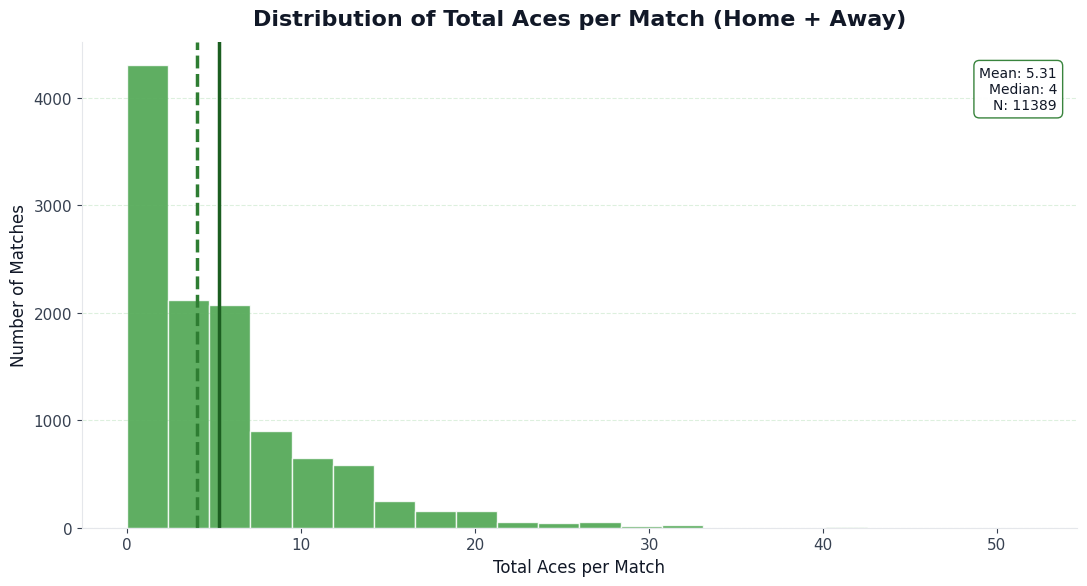

In [ ]:
# =========================
# Q7) Average number of aces per match
# Source: PeriodInfo
# Filter: period=ALL, statistic_category_name=service, statistic_name=aces
# Metric: home + away (aces per match)
# =========================

def _pick_numeric_series(df: pd.DataFrame, candidates: list[str]) -> pd.Series:
    """
    Pick the first candidate column that exists and yields non-null numeric values.
    Converts to numeric safely.
    """
    for col in candidates:
        if col in df.columns:
            s = pd.to_numeric(df[col], errors="coerce")
            if s.notna().any():
                return s
    # if none works, return all-NaN
    return pd.Series([np.nan] * len(df), index=df.index)

# 1) Filter rows (case-insensitive safe)

pi = PeriodInfo.copy()

for c in ["period", "statistic_category_name", "statistic_name"]:
    if c not in pi.columns:
        raise ValueError(f"Column '{c}' not found in PeriodInfo.")

mask = (
    pi["period"].astype(str).str.upper().eq("ALL")
    & pi["statistic_category_name"].astype(str).str.lower().eq("service")
    & pi["statistic_name"].astype(str).str.lower().eq("aces")
)

aces_rows = pi.loc[mask].copy()

if aces_rows.empty:
    raise ValueError("No rows found for (period=ALL, category=service, name=aces).")

# 2) Choose the best numeric source for home/away aces
# Priority: home_value/away_value (int) -> home_total/away_total -> home_stat/away_stat (varchar)
home_aces = _pick_numeric_series(aces_rows, ["home_value", "home_total", "home_stat"])
away_aces = _pick_numeric_series(aces_rows, ["away_value", "away_total", "away_stat"])

aces_rows["home_aces"] = home_aces
aces_rows["away_aces"] = away_aces
aces_rows["aces_total"] = aces_rows["home_aces"] + aces_rows["away_aces"]

# 3) Per-match aces (groupby in case multiple rows per match)
if "match_id" not in aces_rows.columns:
    raise ValueError("Column 'match_id' not found in PeriodInfo.")

aces_per_match = (
    aces_rows.groupby("match_id", as_index=True)["aces_total"]
    .sum(min_count=1)  # keeps NaN if all are NaN for that match
)

# Drop matches with missing/invalid total
aces_per_match_clean = aces_per_match.dropna()

# 4) Summary stats
if aces_per_match_clean.empty:
    raise ValueError("All computed aces per match are NaN. Check which columns contain the numeric values.")

min_v = float(aces_per_match_clean.min())
max_v = float(aces_per_match_clean.max())
mean_v = float(aces_per_match_clean.mean())
median_v = float(aces_per_match_clean.median())

n_matches_total = int(aces_per_match.shape[0])
n_matches_used = int(aces_per_match_clean.shape[0])
n_matches_dropped = n_matches_total - n_matches_used

print("QUESTION 7: What is the average number of aces per match?")
print(f"Matches found (after filter): {n_matches_total}")
print(f"Matches used (valid numeric aces): {n_matches_used} | dropped: {n_matches_dropped}")
print(f"Average aces per match: {mean_v:.2f}")
print(f"Min: {min_v:.0f} | Median: {median_v:.0f} | Max: {max_v:.0f}")

# =========================
# Chart 1: Summary (Min/Median/Avg/Max) - White/Green theme
# =========================
stats_labels = ["Min", "Median", "Average", "Max"]
stats_values = [min_v, median_v, mean_v, max_v]

fig, ax = plt.subplots(figsize=(9.5, 5.5), facecolor="white")
ax.set_facecolor("white")

bars = ax.bar(stats_labels, stats_values, color="#2e7d32", alpha=0.90, edgecolor="white", linewidth=1.2)

ax.set_title("Aces per Match — Summary Statistics", pad=12)
ax.set_ylabel("Aces")
ax.grid(axis="y", linestyle="--", alpha=0.22, color="#66bb6a")

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# Value labels
ymax = max(stats_values)
offset = max(0.5, ymax * 0.02)
for b, v in zip(bars, stats_values):
    ax.text(b.get_x() + b.get_width()/2, v + offset, f"{v:.2f}" if v == mean_v else f"{v:.0f}",
            ha="center", va="bottom", fontsize=10)

plt.tight_layout()
plt.show()

# =========================
# Chart 2: Distribution (Histogram) + Mean/Median lines
# =========================
vals = aces_per_match_clean.values

fig, ax = plt.subplots(figsize=(11, 6), facecolor="white")
ax.set_facecolor("white")

ax.hist(vals, bins=22, color="#43a047", alpha=0.85, edgecolor="white", linewidth=1)

# Mean & Median lines
ax.axvline(mean_v, linewidth=2.5, linestyle="-", color="#1b5e20")
ax.axvline(median_v, linewidth=2.5, linestyle="--", color="#2e7d32")

ax.set_title("Distribution of Total Aces per Match (Home + Away)", pad=12)
ax.set_xlabel("Total Aces per Match")
ax.set_ylabel("Number of Matches")

ax.grid(axis="y", linestyle="--", alpha=0.22, color="#66bb6a")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

ax.text(
    0.98, 0.95,
    f"Mean: {mean_v:.2f}\nMedian: {median_v:.0f}\nN: {n_matches_used}",
    transform=ax.transAxes,
    ha="right", va="top",
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#2e7d32", alpha=0.95)
)

plt.tight_layout()
plt.show()


## QUESTION 8: Difference in double faults based on gender (after outlier removal)

Using raw file: D:\TP\input\PeriodInfo.csv
Matches after filters: 11389
Matches with consistent gender: 8965 | dropped: 2424

Outlier removal report (IQR per gender):


,gender,kept,removed_outliers,total
0,F,3823,126,3949
1,M,4896,120,5016



Cleaned descriptive statistics:


,n,mean,median,std,min,max
match_gender,,,,,,
F,3823.0,6.647920,6.0,3.625600,0.0,16.0
M,4896.0,5.188317,5.0,2.962013,0.0,13.0


C:\Users\ASUS\AppData\Local\Temp\ipykernel_1608\3929165421.py:191: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([male, female], labels=["Men (M)", "Women (F)"], showmeans=True, showfliers=SHOW_FLIERS)


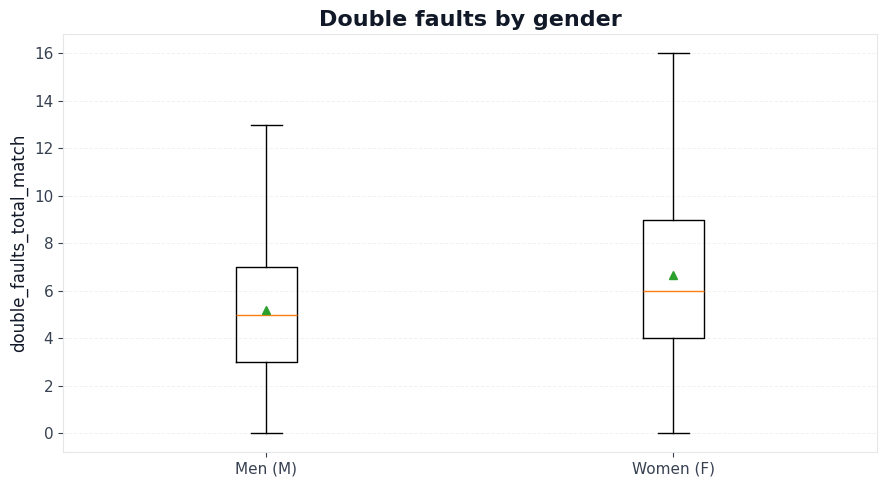


Test results (after cleaning):


,metric,n_M,n_F,mean_M,mean_F,mean_diff_M_minus_F,median_M,median_F,cohens_d_M_minus_F,bootstrap95CI_mean_diff,welch_t_pvalue,mannwhitney_pvalue
0,double_faults_total_match,4896,3823,5.188317,6.64792,-1.459603,5.0,6.0,-0.446418,"(-1.6001435294886979, -1.3164159081214666)",3.463683e-88,3.899337e-76


,match_id,match_gender,home_stat,away_stat,double_faults_total_match,metric
0,11998445,M,2,7,9,9.0
1,11998446,M,2,1,3,3.0
2,11998447,M,0,5,5,5.0
3,11998448,M,2,2,4,4.0
4,11998449,M,2,3,5,5.0
6,11998451,M,4,1,5,5.0
7,11998452,M,0,2,2,2.0
8,11998453,M,4,2,6,6.0
9,11998454,M,1,7,8,8.0
10,11998455,M,1,6,7,7.0


In [ ]:
# Q8 (Clean + Re-run): Difference in double faults based on gender (after outlier removal)
# Files expected in: D:\TP\input
# - MatchHomeTeamInfo.csv
# - MatchAwayTeamInfo.csv

# ---------------- CONFIG ----------------
METRIC = "double_faults_total_match"   # primary metric
IQR_MULT = 1.5                         # 1.5 = standard, 3.0 = looser (removes fewer)
SHOW_FLIERS = True                     # show outliers on the final (cleaned) plot
MIN_MATCHES_PER_GENDER = 30            # sanity threshold for tests (still runs, but warn)
# ---------------------------------------

def norm_gender(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if s in {"m", "male", "men", "man"} or s.startswith("m"):
        return "M"
    if s in {"f", "female", "women", "woman"} or s.startswith("f"):
        return "F"
    if "men" in s:
        return "M"
    if "women" in s:
        return "F"
    return np.nan

def to_num(s):
    return pd.to_numeric(s, errors="coerce")

def iqr_filter(series: pd.Series, mult: float) -> pd.Series:
    x = pd.to_numeric(series, errors="coerce").dropna()
    if x.empty:
        return pd.Series([True] * len(series), index=series.index)
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1
    lower = max(0.0, float(q1 - mult * iqr))
    upper = float(q3 + mult * iqr)
    return series.between(lower, upper, inclusive="both")

def cohens_d(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x = x[np.isfinite(x)]
    y = y[np.isfinite(y)]
    if len(x) < 2 or len(y) < 2:
        return np.nan
    vx = np.var(x, ddof=1)
    vy = np.var(y, ddof=1)
    sp = np.sqrt(((len(x)-1)*vx + (len(y)-1)*vy) / (len(x)+len(y)-2))
    if sp == 0:
        return 0.0
    return (np.mean(x) - np.mean(y)) / sp

def bootstrap_ci_mean_diff(x, y, n=8000, alpha=0.05, seed=42):
    rng = np.random.default_rng(seed)
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x = x[np.isfinite(x)]
    y = y[np.isfinite(y)]
    if len(x) == 0 or len(y) == 0:
        return (np.nan, np.nan)
    diffs = []
    for _ in range(n):
        xb = rng.choice(x, size=len(x), replace=True)
        yb = rng.choice(y, size=len(y), replace=True)
        diffs.append(np.mean(xb) - np.mean(yb))
    lo = np.quantile(diffs, alpha/2)
    hi = np.quantile(diffs, 1 - alpha/2)
    return (float(lo), float(hi))

# ---------------- 1) Load + filter raw statistics ----------------
raw_path = find_csv(DATA_DIR, ["Periodinfo.csv", "raw_statistics.csv"])
raw = pd.read_csv(raw_path)
raw.columns = [c.strip() for c in raw.columns]

need = ["match_id", "period", "statistic_category_name", "statistic_name", "home_stat", "away_stat"]
missing = [c for c in need if c not in raw.columns]
if missing:
    raise KeyError(f"Missing columns in {raw_path.name}: {missing}")

tmp = raw.copy()
tmp["period"] = tmp["period"].astype(str).str.strip()
tmp["statistic_category_name"] = tmp["statistic_category_name"].astype(str).str.strip().str.lower()
tmp["statistic_name"] = tmp["statistic_name"].astype(str).str.strip().str.lower()

df = tmp[
    (tmp["period"].str.upper() == "ALL") &
    (tmp["statistic_category_name"] == "service") &
    (tmp["statistic_name"] == "double_faults")
].copy()

df["match_id"] = to_num(df["match_id"])
df["home_stat"] = to_num(df["home_stat"])
df["away_stat"] = to_num(df["away_stat"])
df = df.dropna(subset=["match_id"]).copy()
df["match_id"] = df["match_id"].astype("int64")

# if multiple rows per match remain, collapse to one record (max is robust against duplicates)
df = (
    df.groupby("match_id", as_index=False)
      .agg(home_stat=("home_stat", "max"),
           away_stat=("away_stat", "max"))
)

df["double_faults_total_match"] = df["home_stat"].fillna(0) + df["away_stat"].fillna(0)
df["double_faults_avg_player"] = df["double_faults_total_match"] / 2.0

print("Using raw file:", raw_path)
print("Matches after filters:", df["match_id"].nunique())

# ---------------- 2) Load genders from Home/Away team info ----------------
home_path = MatchHomeTeamInfo_path
away_path = MatchAwayTeamInfo_path
home = MatchHomeTeamInfo.copy(); home.columns = [c.strip() for c in home.columns]
away = MatchAwayTeamInfo.copy(); away.columns = [c.strip() for c in away.columns]
if "match_id" not in home.columns or "match_id" not in away.columns:
    raise KeyError("Expected 'match_id' in MatchHomeTeamInfo.csv and MatchAwayTeamInfo.csv")

gcol_h = pick_col(home, ["gender"])
gcol_a = pick_col(away, ["gender"])
if not gcol_h or not gcol_a:
    raise KeyError("Could not find 'gender' column in Home/Away TeamInfo CSVs")

hg = home[["match_id", gcol_h]].rename(columns={gcol_h: "gender_home"}).copy()
ag = away[["match_id", gcol_a]].rename(columns={gcol_a: "gender_away"}).copy()

hg["match_id"] = to_num(hg["match_id"]); ag["match_id"] = to_num(ag["match_id"])
hg = hg.dropna(subset=["match_id"]); ag = ag.dropna(subset=["match_id"])
hg["match_id"] = hg["match_id"].astype("int64"); ag["match_id"] = ag["match_id"].astype("int64")

hg["gender_home"] = hg["gender_home"].apply(norm_gender)
ag["gender_away"] = ag["gender_away"].apply(norm_gender)

analysis_df = df.merge(hg, on="match_id", how="left").merge(ag, on="match_id", how="left")

# tennis should be same gender on both sides; keep only consistent
analysis_df["match_gender"] = np.where(
    analysis_df["gender_home"].notna() &
    (analysis_df["gender_home"] == analysis_df["gender_away"]),
    analysis_df["gender_home"],
    np.nan
)

before = len(analysis_df)
analysis_df = analysis_df.dropna(subset=["match_gender"]).copy()
print("Matches with consistent gender:", len(analysis_df), "| dropped:", before - len(analysis_df))

# ---------------- 3) Outlier removal (IQR per gender) ----------------
analysis_df["metric"] = analysis_df[METRIC].astype(float)

mask_by_gender = []
removed_report = []

for g, sub in analysis_df.groupby("match_gender"):
    m = iqr_filter(sub["metric"], IQR_MULT)
    kept = int(m.sum())
    dropped = int((~m).sum())
    removed_report.append({"gender": g, "kept": kept, "removed_outliers": dropped, "total": len(sub)})
    mask_by_gender.append(m)

mask = pd.concat(mask_by_gender).sort_index()
clean_df = analysis_df[mask].copy()

print("\nOutlier removal report (IQR per gender):")
display(pd.DataFrame(removed_report))

# ---------------- 4) Summary + Plot (cleaned) ----------------
def summarize(x: pd.Series):
    x = pd.to_numeric(x, errors="coerce").dropna()
    return pd.Series({
        "n": len(x),
        "mean": x.mean(),
        "median": x.median(),
        "std": x.std(ddof=1),
        "min": x.min(),
        "max": x.max()
    })

summary = clean_df.groupby("match_gender")["metric"].apply(summarize).unstack()
print("\nCleaned descriptive statistics:")
display(summary)

male = clean_df.loc[clean_df["match_gender"] == "M", "metric"].dropna().to_numpy(dtype=float)
female = clean_df.loc[clean_df["match_gender"] == "F", "metric"].dropna().to_numpy(dtype=float)

if len(male) < MIN_MATCHES_PER_GENDER or len(female) < MIN_MATCHES_PER_GENDER:
    print(f"Warning: low sample size for tests (M={len(male)}, F={len(female)}). Results may be unstable.")

plt.figure(figsize=(9, 5))
plt.boxplot([male, female], labels=["Men (M)", "Women (F)"], showmeans=True, showfliers=SHOW_FLIERS)
plt.title(f"Double faults by gender")
plt.ylabel('double_faults_total_match')
plt.grid(True, axis="y", linestyle="--", linewidth=0.7)
plt.tight_layout()
plt.show()

# ---------------- 5) Statistical tests (after cleaning) ----------------
results = {
    "metric": METRIC,
    "n_M": int(len(male)),
    "n_F": int(len(female)),
    "mean_M": float(np.mean(male)) if len(male) else np.nan,
    "mean_F": float(np.mean(female)) if len(female) else np.nan,
    "mean_diff_M_minus_F": float(np.mean(male) - np.mean(female)) if (len(male) and len(female)) else np.nan,
    "median_M": float(np.median(male)) if len(male) else np.nan,
    "median_F": float(np.median(female)) if len(female) else np.nan,
    "cohens_d_M_minus_F": float(cohens_d(male, female)),
    "bootstrap95CI_mean_diff": bootstrap_ci_mean_diff(male, female),
}

try:
    t = stats.ttest_ind(male, female, equal_var=False, nan_policy="omit")  # Welch t-test
    u = stats.mannwhitneyu(male, female, alternative="two-sided")
    results["welch_t_pvalue"] = float(t.pvalue)
    results["mannwhitney_pvalue"] = float(u.pvalue)
except Exception as e:
    # permutation test fallback
    rng = np.random.default_rng(42)
    x = male.copy()
    y = female.copy()
    obs = np.mean(x) - np.mean(y)
    pool = np.concatenate([x, y])
    n_x = len(x)
    n_perm = 5000
    diffs = []
    for _ in range(n_perm):
        rng.shuffle(pool)
        diffs.append(np.mean(pool[:n_x]) - np.mean(pool[n_x:]))
    diffs = np.asarray(diffs)
    p = np.mean(np.abs(diffs) >= abs(obs))
    results["permutation_pvalue"] = float(p)
    results["note"] = f"SciPy not available; used permutation test. ({type(e).__name__})"

print("\nTest results (after cleaning):")
display(pd.DataFrame([results]))

# keep cleaned dataset for later
clean_analysis_df = clean_df[["match_id", "match_gender", "home_stat", "away_stat", METRIC, "metric"]].copy()
clean_analysis_df.head(20)


## QUESTION 9: Which player has won the most tournaments in a single month?

In [ ]:
# Question 9: 

print("Loading required files...")
event      = MatchEventInfo[['match_id', 'winner_code', 'start_datetime']].copy()
tourn      = MatchTournamentInfo[['match_id', 'tournament_id']].copy()
round_info = MatchRoundInfo[['match_id', 'name']].copy()
home       = MatchHomeTeamInfo[['match_id', 'full_name']].copy()
away       = MatchAwayTeamInfo[['match_id', 'full_name']].copy()

finals = (
    event
    .merge(tourn,      on='match_id', how='left')
    .merge(round_info, on='match_id', how='inner')
    .query("name == 'Final'")
    .merge(home.rename(columns={'full_name': 'home_player'}), on='match_id', how='left')
    .merge(away.rename(columns={'full_name': 'away_player'}), on='match_id', how='left')
)

finals['winner_name'] = finals.apply(
    lambda r: r['home_player'] if r['winner_code'] == 1 else r['away_player'],
    axis=1
)

finals['date'] = pd.to_datetime(finals['start_datetime'], unit='s')
finals['year_month'] = finals['date'].dt.to_period('M')
finals['month_display'] = finals['date'].dt.strftime('%B %Y')

monthly_wins = (
    finals.groupby(['year_month', 'month_display', 'winner_name'])['tournament_id']
    .nunique()
    .reset_index(name='tournaments_won')
    .sort_values(['tournaments_won', 'year_month'], ascending=[False, True])
)

max_wins = monthly_wins['tournaments_won'].max()

print(f"Maximum tournaments won in a single month: {max_wins}")
print(f"Total tournament finals in dataset: {len(finals):,}\n")

# TABLE 
# Top players 
top_players_table = monthly_wins[monthly_wins['tournaments_won'] == max_wins][['month_display', 'winner_name', 'tournaments_won']]

print("Player(s) with the most titles in one month:")
display(top_players_table)

# Full ranking table 
print("\nFull monthly title ranking:")
full_table = monthly_wins[['month_display', 'winner_name', 'tournaments_won']].copy()
display(full_table)


Loading required files...
Maximum tournaments won in a single month: 3
Total tournament finals in dataset: 260

Player(s) with the most titles in one month:


,month_display,winner_name,tournaments_won
26,February 2024,"Gengel, Marek",3
69,February 2024,"Popko, Dmitry",3
120,March 2024,"Faria, Jaime",3
132,March 2024,"Helgo, Malene",3
143,March 2024,"Jianu, Filip Cristian",3
173,March 2024,"Nicod, Jakub",3



Full monthly title ranking:


,month_display,winner_name,tournaments_won
26,February 2024,"Gengel, Marek",3
69,February 2024,"Popko, Dmitry",3
120,March 2024,"Faria, Jaime",3
132,March 2024,"Helgo, Malene",3
143,March 2024,"Jianu, Filip Cristian",3
...,...,...,...
220,March 2024,"Zaytseva, Ksenia",1
221,March 2024,"Zelníčková, Radka",1
222,March 2024,"de Minaur, Alex",1
223,March 2024,"van Wyk, Kris",1


## QUESTION 10: Is there a correlation between a player's height and their ranking?

QUESTION 10: Is there a correlation between a player's height and their ranking?
N valid players: 1335
Pearson r (linear):  0.1055
Spearman rho (rank): 0.1018
Note: Lower rank number means better ranking, so a negative correlation suggests taller players tend to have better ranks (lower numbers).


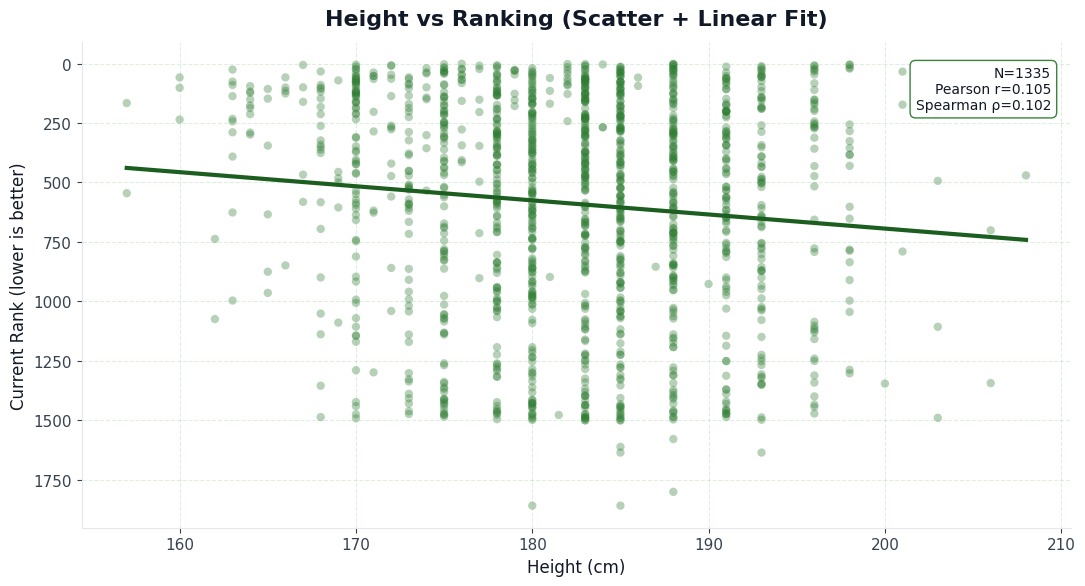

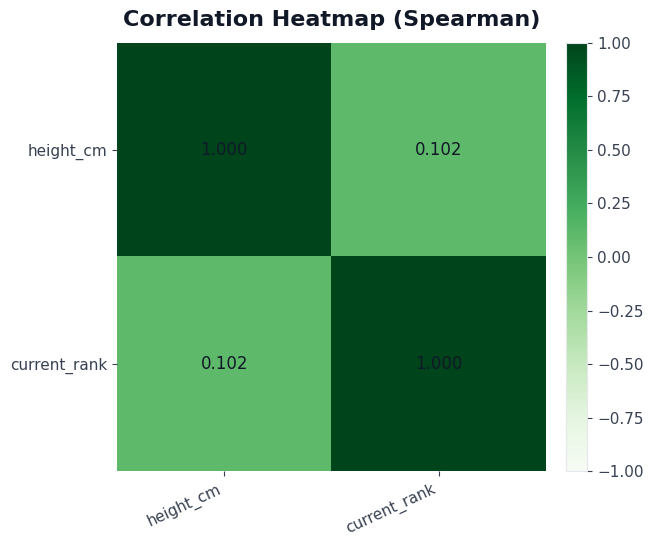

In [ ]:
# =========================
# Helpers
# =========================

def build_unique_players_for_rank(home_df: pd.DataFrame, away_df: pd.DataFrame) -> pd.DataFrame:
    keep = ["player_id", "name_code", "full_name", "country", "gender", "height", "current_rank"]
    home = home_df[[c for c in keep if c in home_df.columns]].copy()
    away = away_df[[c for c in keep if c in away_df.columns]].copy()
    allp = pd.concat([home, away], ignore_index=True)

    allp["height"] = pd.to_numeric(allp.get("height"), errors="coerce")
    allp["current_rank"] = pd.to_numeric(allp.get("current_rank"), errors="coerce")

    # Unique key: player_id -> name_code -> full_name|country|gender
    key = pd.Series(np.nan, index=allp.index, dtype="object")

    if "player_id" in allp.columns:
        key = allp["player_id"].where(allp["player_id"].notna(), np.nan).astype("object")

    if "name_code" in allp.columns:
        key = key.where(
            key.notna(),
            allp["name_code"].where(allp["name_code"].notna(), np.nan).astype("object"),
        )

    fn = allp["full_name"] if "full_name" in allp.columns else pd.Series(np.nan, index=allp.index)
    co = allp["country"] if "country" in allp.columns else pd.Series("", index=allp.index)
    ge = allp["gender"] if "gender" in allp.columns else pd.Series("", index=allp.index)

    combo_key = (
        fn.fillna("").astype(str).str.strip()
        + " | "
        + co.fillna("").astype(str).str.strip()
        + " | "
        + ge.fillna("").astype(str).str.strip()
    )
    combo_key = combo_key.replace(" |  | ", np.nan)

    key = key.where(key.notna(), combo_key.astype("object"))
    allp["__unique_key__"] = key
    allp = allp.dropna(subset=["__unique_key__"])

    # Aggregate per player (robust)
    agg = allp.groupby("__unique_key__", as_index=False).agg(
        player_id=("player_id", "first"),
        name_code=("name_code", "first"),
        full_name=("full_name", "first"),
        country=("country", "first"),
        gender=("gender", "first"),
        height=("height", "median"),
        current_rank=("current_rank", "median"),
    )
    return agg


def normalize_height_to_cm(h: pd.Series) -> pd.Series:
    h_clean = h.dropna()
    if h_clean.empty:
        return h
    med = float(h_clean.median())
    # meters -> cm
    if 0.5 < med < 3.5:
        return h * 100.0
    return h


def spearman_corr_no_scipy(x: pd.Series, y: pd.Series) -> float:
    """
    Spearman correlation without scipy:
    Spearman = Pearson(corr(rank(x), rank(y))).
    Handles ties using average ranks (pandas default).
    """
    df_ = pd.DataFrame({"x": x, "y": y}).dropna()
    if len(df_) < 2:
        return np.nan
    rx = df_["x"].rank(method="average")
    ry = df_["y"].rank(method="average")
    return float(rx.corr(ry, method="pearson"))


# =========================
# Q10) Correlation between height and ranking
# =========================

players = build_unique_players_for_rank(MatchHomeTeamInfo, MatchAwayTeamInfo)

players["height_cm"] = normalize_height_to_cm(players["height"])
players["height_cm"] = players["height_cm"].where((players["height_cm"] >= 100) & (players["height_cm"] <= 250), np.nan)

players["current_rank"] = players["current_rank"].where(players["current_rank"] > 0, np.nan)

df = players[["height_cm", "current_rank"]].dropna().copy()
if df.empty:
    raise ValueError("No valid (height, rank) pairs after cleaning. Check your data quality.")

pearson_r = float(df["height_cm"].corr(df["current_rank"], method="pearson"))
spearman_r = spearman_corr_no_scipy(df["height_cm"], df["current_rank"])

print("QUESTION 10: Is there a correlation between a player's height and their ranking?")
print(f"N valid players: {len(df)}")
print(f"Pearson r (linear):  {pearson_r:.4f}")
print(f"Spearman rho (rank): {spearman_r:.4f}")
print("Note: Lower rank number means better ranking, so a negative correlation suggests taller players tend to have better ranks (lower numbers).")

# =========================
# Plot 1: Regplot-style (scatter + linear fit)
# =========================

x = df["height_cm"].to_numpy()
y = df["current_rank"].to_numpy()

a, b = np.polyfit(x, y, 1)
xx = np.linspace(x.min(), x.max(), 250)
yy = a * xx + b

fig, ax = plt.subplots(figsize=(11, 6), facecolor="white")
ax.set_facecolor("white")

ax.scatter(x, y, alpha=0.35, edgecolor="none", color="#2e7d32")
ax.plot(xx, yy, linewidth=3.0, color="#1b5e20")

ax.set_title("Height vs Ranking (Scatter + Linear Fit)", pad=12)
ax.set_xlabel("Height (cm)")
ax.set_ylabel("Current Rank (lower is better)")
ax.grid(True, linestyle="--", alpha=0.22, color="#66bb6a")

# nicer for ranks: better ranks appear higher
ax.invert_yaxis()

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

ax.text(
    0.98, 0.95,
    f"N={len(df)}\nPearson r={pearson_r:.3f}\nSpearman ρ={spearman_r:.3f}",
    transform=ax.transAxes,
    ha="right", va="top",
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#2e7d32", alpha=0.95)
)

plt.tight_layout()
plt.show()

# =========================
# Plot 2: Heatmap (Spearman) — more appropriate for ranking
# =========================

# Build a 2x2 Spearman correlation matrix without scipy
rho = spearman_corr_no_scipy(df["height_cm"], df["current_rank"])
corr_spearman = np.array([[1.0, rho], [rho, 1.0]])

labels = ["height_cm", "current_rank"]

fig, ax = plt.subplots(figsize=(6.6, 5.6), facecolor="white")
ax.set_facecolor("white")

im = ax.imshow(corr_spearman, cmap="Greens", vmin=-1, vmax=1)

ax.set_title("Correlation Heatmap (Spearman)", pad=12)
ax.set_xticks(range(2))
ax.set_yticks(range(2))
ax.set_xticklabels(labels, rotation=25, ha="right")
ax.set_yticklabels(labels)

for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{corr_spearman[i, j]:.3f}", ha="center", va="center", fontsize=12)

for spine in ["top", "right", "left", "bottom"]:
    ax.spines[spine].set_visible(False)

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


## QUESTION 11: What is the average duration of matches?

Loading: D:\TP\input\MatchTimeInfo.csv

RAW duration (minutes) percentiles:
  p50.0: 96.8 min
  p90.0: 154.7 min
  p95.0: 174.7 min
  p99.0: 295.2 min
  p99.5: 1160.4 min
  p99.9: 2664.3 min
  max: 5613.2 min

Top 20 longest (raw):


,match_id,duration_min
3097,12063611,5613.166667
3079,12063587,5337.166667
14674,12185562,2952.183333
8300,12121829,2890.250000
2120,12054403,2731.383333
3080,12063588,2717.216667
3076,12063582,2705.733333
3081,12063589,2703.183333
3100,12063615,2696.766667
2105,12053865,2680.416667



SUMMARY:
  raw n=10,327 | clean n=10,215 | removed=112 (1.08%)
  RAW   mean=114.7 min | median=96.8 min
  CLEAN mean=103.2 min | median=96.5 min
  CLEAN max=326.4 min


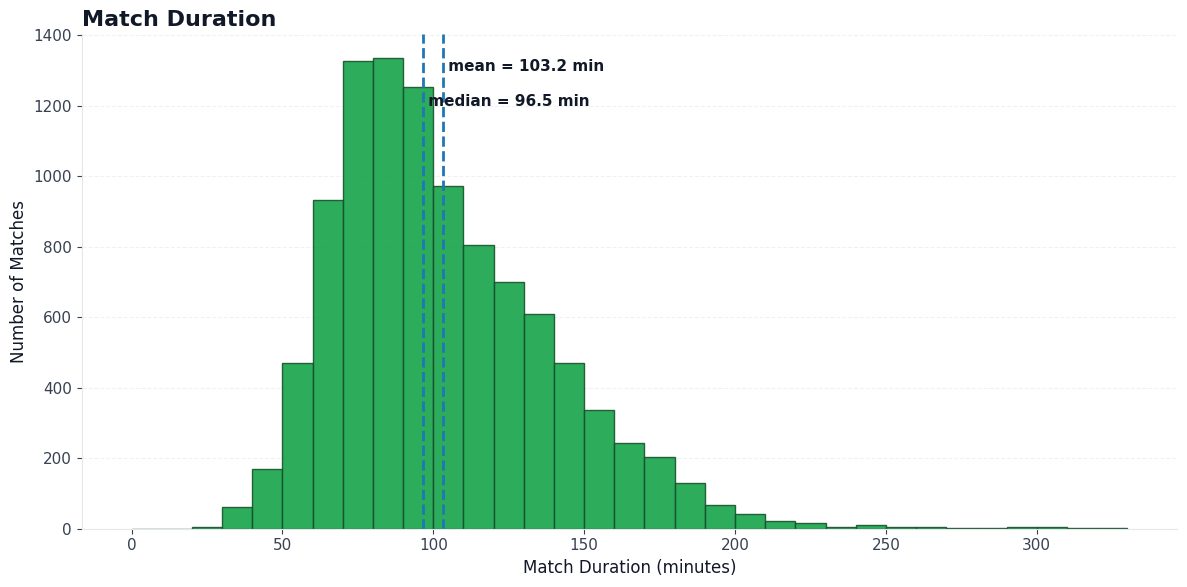

In [ ]:
path = MatchTimeInfo_path
print("Loading:", path)

# ---------- params ----------
MIN_MINUTES = 10           
MAX_MINUTES = 720         
ROBUST_Z_MAX = 3.5        
SHOW_TOP_OUTLIERS = 20
# --------------------------

def set_clean_theme():
    plt.style.use("default")
    plt.rcParams.update({
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "axes.edgecolor": "#E5E7EB",
        "axes.labelcolor": "#111827",
        "xtick.color": "#374151",
        "ytick.color": "#374151",
        "text.color": "#111827",
        "font.size": 11,
        "axes.titlesize": 16,
        "axes.titleweight": "bold",
        "axes.labelsize": 12,
        "grid.color": "#E5E7EB",
        "grid.linestyle": "--",
        "grid.linewidth": 0.8,
        "grid.alpha": 0.55,
    })

set_clean_theme()
df = MatchTimeInfo.copy()
# columns
period_cols = [c for c in df.columns if str(c).lower().startswith("period_")]
if not period_cols:
    raise ValueError("No period_* columns found in MatchTimeInfo.csv")

match_id_col = None
for c in ["match_id", "matchId", "id", "matchID"]:
    if c in df.columns:
        match_id_col = c
        break

for c in period_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# duration (sec) - min_count=1 prevents all-NaN rows becoming 0
df["duration_sec"] = df[period_cols].sum(axis=1, min_count=1)

dur_sec = df["duration_sec"].replace([np.inf, -np.inf], np.nan).dropna()
dur_sec = dur_sec[dur_sec > 0].copy()

# quick sanity: if values look like milliseconds (very large median), convert
if dur_sec.median() > 1_000_000:  # ~11.6 days in seconds; likely ms
    dur_sec = dur_sec / 1000.0
    print("Note: durations looked like milliseconds -> divided by 1000")

dur_min = dur_sec / 60.0

# print raw tail to see the problem
print("\nRAW duration (minutes) percentiles:")
for q in [0.5, 0.9, 0.95, 0.99, 0.995, 0.999]:
    print(f"  p{int(q*1000)/10:.1f}: {dur_min.quantile(q):.1f} min")
print(f"  max: {dur_min.max():.1f} min")

# show top outliers (raw)
if match_id_col:
    tmp = df[[match_id_col, "duration_sec"]].copy()
    tmp["duration_min"] = tmp["duration_sec"] / 60.0
    top = tmp.sort_values("duration_min", ascending=False).head(SHOW_TOP_OUTLIERS)
    print(f"\nTop {SHOW_TOP_OUTLIERS} longest (raw):")
    display(top[[match_id_col, "duration_min"]])

# ---- cleaning step 1: hard bounds ----
mask_bounds = (dur_min >= MIN_MINUTES) & (dur_min <= MAX_MINUTES)
dur_min_bounded = dur_min[mask_bounds].copy()

# ---- cleaning step 2: robust MAD filter on log scale ----
x = np.log1p(dur_min_bounded.values)
med = np.median(x)
mad = np.median(np.abs(x - med))

if mad == 0:
    dur_min_clean = dur_min_bounded
else:
    robust_z = 0.6745 * (x - med) / mad
    dur_min_clean = dur_min_bounded[np.abs(robust_z) <= ROBUST_Z_MAX].copy()

removed = len(dur_min) - len(dur_min_clean)

raw_mean = float(dur_min.mean())
raw_med  = float(dur_min.median())
cln_mean = float(dur_min_clean.mean())
cln_med  = float(dur_min_clean.median())

print("\nSUMMARY:")
print(f"  raw n={len(dur_min):,} | clean n={len(dur_min_clean):,} | removed={removed:,} ({removed/len(dur_min)*100:.2f}%)")
print(f"  RAW   mean={raw_mean:.1f} min | median={raw_med:.1f} min")
print(f"  CLEAN mean={cln_mean:.1f} min | median={cln_med:.1f} min")
print(f"  CLEAN max={dur_min_clean.max():.1f} min")

# ---- plot ----
fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

max_min = float(dur_min_clean.max())
bin_step = 10
bins = np.arange(0, max_min + bin_step, bin_step)

ax.hist(dur_min_clean, bins=bins, color="#16A34A", edgecolor="#14532D", alpha=0.9)

ax.axvline(cln_mean, linestyle="--", linewidth=2)
ax.axvline(cln_med,  linestyle="--", linewidth=2)

ax.text(cln_mean, ax.get_ylim()[1]*0.95, f" mean = {cln_mean:.1f} min", ha="left", va="top", fontweight="bold")
ax.text(cln_med,  ax.get_ylim()[1]*0.88, f" median = {cln_med:.1f} min", ha="left", va="top", fontweight="bold")

ax.set_title("Match Duration",loc='left' )
ax.set_xlabel("Match Duration (minutes)")
ax.set_ylabel("Number of Matches")

plt.tight_layout()
plt.show()

## QUESTION 12: Average games per set by gender

Using GameInfo: D:\TP\input\GameInfo.csv
Unique sets: 25090
Unique matches: 10956
Matches with consistent gender: 9858 | dropped: 781
Sets after gender join: 19905
Sets by gender:
 match_gender
M    11179
F     8726
Name: count, dtype: int64

Set-level games per set by gender:


,match_gender,n_sets,mean,median,std,min,max
0,F,8726,9.043777,9.0,2.146424,1,13
1,M,11179,9.430808,9.0,2.184733,1,13


C:\Users\ASUS\AppData\Local\Temp\ipykernel_1608\991745343.py:134: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([men, women], labels=["Men (M)", "Women (F)"], showmeans=True, showfliers=SHOW_FLIERS)


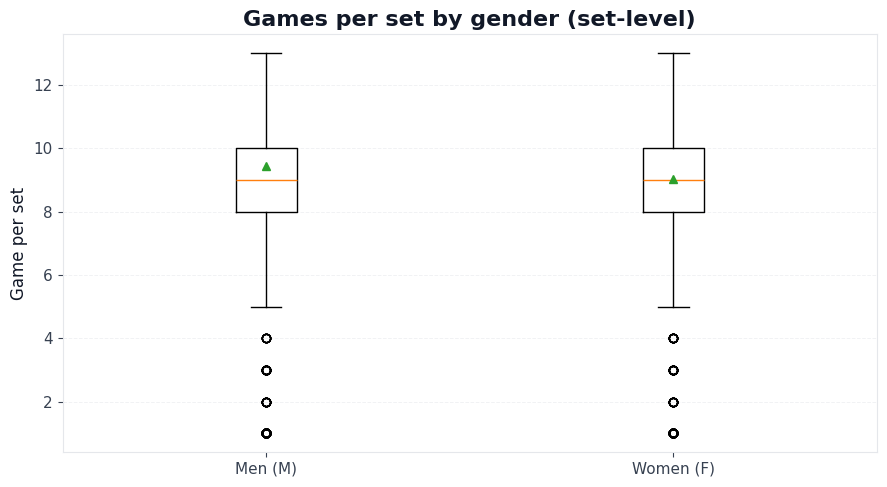

,match_id,set_id,games_in_set,match_gender
0,11998445,1,12,M
1,11998445,2,8,M
2,11998445,3,13,M
3,11998446,1,10,M
4,11998446,2,7,M
5,11998447,1,10,M
6,11998447,2,6,M
7,11998448,1,10,M
8,11998448,2,10,M
9,11998449,1,7,M


In [ ]:

# ---------------- CONFIG ----------------
DROP_INCONSISTENT_GENDER = True
PLOT = True
SHOW_FLIERS = True  # show outliers in boxplot
# ----------------------------------------

def find_csv(base: Path, candidates: list[str]) -> Path:
    lc = {c.lower() for c in candidates}
    for p in base.rglob("*.csv"):
        if p.name.lower() in lc:
            return p
    raise FileNotFoundError(f"None of these files found under {base}: {candidates}")

def pick_col(df: pd.DataFrame, candidates: list[str]) -> str | None:
    cols = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in cols:
            return cols[cand.lower()]
    return None

def to_num(s):
    return pd.to_numeric(s, errors="coerce")

def norm_gender(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if s in {"m", "male", "men", "man"} or s.startswith("m") or "men" in s:
        return "M"
    if s in {"f", "female", "women", "woman"} or s.startswith("f") or "women" in s:
        return "F"
    return np.nan

# ---------------- 1) Load GameInfo and compute games per set ----------------
game_path = find_csv(DATA_DIR, ["GameInfo.csv"])
g = pd.read_csv(game_path)
g.columns = [c.strip() for c in g.columns]

need = ["match_id", "set_id", "game_id"]
missing = [c for c in need if c not in g.columns]
if missing:
    raise KeyError(f"Missing columns in {game_path.name}: {missing}")

g["match_id"] = to_num(g["match_id"])
g["set_id"] = to_num(g["set_id"])
g["game_id"] = to_num(g["game_id"])

g = g.dropna(subset=["match_id", "set_id", "game_id"]).copy()
g["match_id"] = g["match_id"].astype("int64")
g["set_id"] = g["set_id"].astype("int64")
g["game_id"] = g["game_id"].astype("int64")

# point-level -> unique games
games_unique = g.drop_duplicates(subset=["match_id", "set_id", "game_id"]).copy()

# set-level dataset
set_level_df = (
    games_unique
    .groupby(["match_id", "set_id"], as_index=False)
    .agg(games_in_set=("game_id", "nunique"))
)

print("Using GameInfo:", game_path)
print("Unique sets:", len(set_level_df))
print("Unique matches:", set_level_df["match_id"].nunique())

# ---------------- 2) Infer match gender from Home/Away TeamInfo ----------------
home_path = find_csv(DATA_DIR, ["MatchHomeTeamInfo.csv"])
away_path = find_csv(DATA_DIR, ["MatchAwayTeamInfo.csv"])

home = pd.read_csv(home_path); home.columns = [c.strip() for c in home.columns]
away = pd.read_csv(away_path); away.columns = [c.strip() for c in away.columns]

if "match_id" not in home.columns or "match_id" not in away.columns:
    raise KeyError("Expected 'match_id' in MatchHomeTeamInfo.csv and MatchAwayTeamInfo.csv")

gcol_h = pick_col(home, ["gender"])
gcol_a = pick_col(away, ["gender"])
if not gcol_h or not gcol_a:
    raise KeyError("Could not find 'gender' column in Home/Away TeamInfo CSVs")

hg = home[["match_id", gcol_h]].rename(columns={gcol_h: "gender_home"}).copy()
ag = away[["match_id", gcol_a]].rename(columns={gcol_a: "gender_away"}).copy()

hg["match_id"] = to_num(hg["match_id"]); ag["match_id"] = to_num(ag["match_id"])
hg = hg.dropna(subset=["match_id"]); ag = ag.dropna(subset=["match_id"])
hg["match_id"] = hg["match_id"].astype("int64"); ag["match_id"] = ag["match_id"].astype("int64")

hg["gender_home"] = hg["gender_home"].apply(norm_gender)
ag["gender_away"] = ag["gender_away"].apply(norm_gender)

gender_by_match = hg.merge(ag, on="match_id", how="inner")

if DROP_INCONSISTENT_GENDER:
    gender_by_match["match_gender"] = np.where(
        gender_by_match["gender_home"].notna() &
        (gender_by_match["gender_home"] == gender_by_match["gender_away"]),
        gender_by_match["gender_home"],
        np.nan
    )
    before = len(gender_by_match)
    gender_by_match = gender_by_match.dropna(subset=["match_gender"]).copy()
    print("Matches with consistent gender:", len(gender_by_match), "| dropped:", before - len(gender_by_match))
else:
    gender_by_match["match_gender"] = gender_by_match["gender_home"].fillna(gender_by_match["gender_away"])

gender_by_match = gender_by_match[["match_id", "match_gender"]].drop_duplicates("match_id")

# ---------------- 3) Join gender into set-level data ----------------
set_level_df = set_level_df.merge(gender_by_match, on="match_id", how="inner")
set_level_df = set_level_df.dropna(subset=["match_gender", "games_in_set"]).copy()

print("Sets after gender join:", len(set_level_df))
print("Sets by gender:\n", set_level_df["match_gender"].value_counts())

# ---------------- 4) Summary (Men vs Women) ----------------
summary = (
    set_level_df
    .groupby("match_gender")["games_in_set"]
    .agg(n_sets="count", mean="mean", median="median", std="std", min="min", max="max")
    .reset_index()
    .sort_values("match_gender")
)

print("\nSet-level games per set by gender:")
display(summary)

# ---------------- 5) Plot ----------------
if PLOT:
    men = set_level_df.loc[set_level_df["match_gender"] == "M", "games_in_set"].to_numpy(dtype=float)
    women = set_level_df.loc[set_level_df["match_gender"] == "F", "games_in_set"].to_numpy(dtype=float)

    plt.figure(figsize=(9, 5))
    plt.boxplot([men, women], labels=["Men (M)", "Women (F)"], showmeans=True, showfliers=SHOW_FLIERS)
    plt.title("Games per set by gender (set-level)")
    plt.ylabel("Game per set")
    plt.grid(True, axis="y", linestyle="--", linewidth=0.7)
    plt.tight_layout()
    plt.show()

# keep for reuse
set_level_df.head(20)

## QUESTION 13: Left-handed vs right-handed distribution

13. What is the distribution of left-handed versus right-handed players?

QUESTION 13: What is the distribution of lefthanded versus right-handed players?
Total unique players: 2644
Right-handed: 1013 (38.3%)
Left-handed:  133 (5.0%)
Unknown/Other:1498 (56.7%)


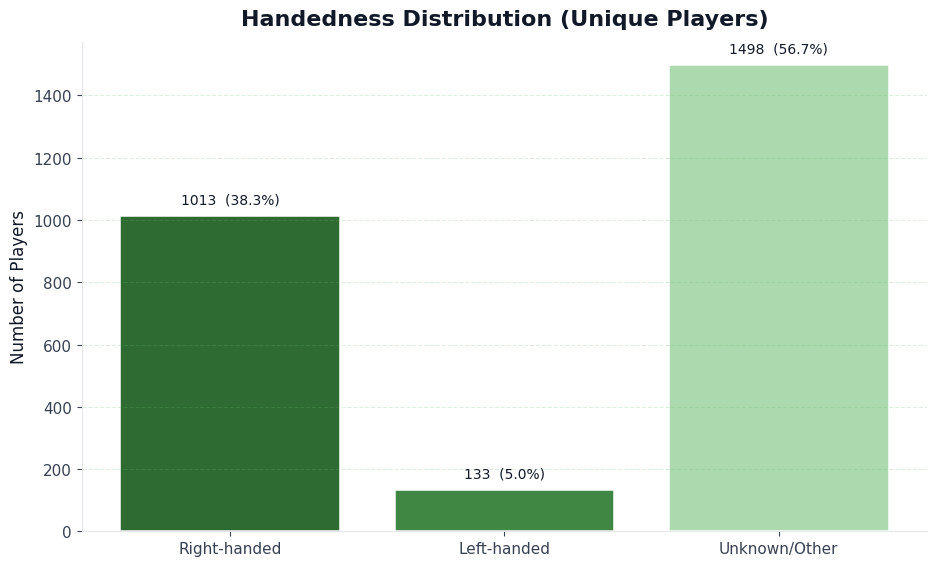

In [ ]:

# =========================
# Q13) Distribution of left-handed vs right-handed players
# =========================

def build_unique_players_with_plays(home_df: pd.DataFrame, away_df: pd.DataFrame) -> pd.DataFrame:
    keep = ["player_id", "name_code", "full_name", "country", "gender", "plays"]
    home = home_df[[c for c in keep if c in home_df.columns]].copy()
    away = away_df[[c for c in keep if c in away_df.columns]].copy()
    allp = pd.concat([home, away], ignore_index=True)

    # robust unique key: player_id -> name_code -> full_name|country|gender
    key = pd.Series(np.nan, index=allp.index, dtype="object")

    if "player_id" in allp.columns:
        key = allp["player_id"].where(allp["player_id"].notna(), np.nan).astype("object")

    if "name_code" in allp.columns:
        key = key.where(
            key.notna(),
            allp["name_code"].where(allp["name_code"].notna(), np.nan).astype("object"),
        )

    fn = allp["full_name"] if "full_name" in allp.columns else pd.Series(np.nan, index=allp.index)
    co = allp["country"] if "country" in allp.columns else pd.Series("", index=allp.index)
    ge = allp["gender"] if "gender" in allp.columns else pd.Series("", index=allp.index)

    combo_key = (
        fn.fillna("").astype(str).str.strip()
        + " | "
        + co.fillna("").astype(str).str.strip()
        + " | "
        + ge.fillna("").astype(str).str.strip()
    )
    combo_key = combo_key.replace(" |  | ", np.nan)

    key = key.where(key.notna(), combo_key.astype("object"))
    allp["__unique_key__"] = key
    allp = allp.dropna(subset=["__unique_key__"])

    # Aggregate to one row per player; take the most frequent 'plays' value (mode)
    def mode_or_nan(s):
        s = s.dropna()
        if s.empty:
            return np.nan
        m = s.mode()
        return m.iloc[0] if len(m) else np.nan

    players = allp.groupby("__unique_key__", as_index=False).agg(
        player_id=("player_id", "first"),
        name_code=("name_code", "first"),
        full_name=("full_name", "first"),
        country=("country", "first"),
        gender=("gender", "first"),
        plays=("plays", mode_or_nan),
    )
    return players


def normalize_handedness(v) -> str:
    """
    Map 'plays' values to Left/Right/Unknown.
    Handles typical variants (case-insensitive).
    """
    if pd.isna(v):
        return "Unknown/Other"
    s = str(v).strip().lower()

    # Common representations across sports data
    # Tennis style: "Right-handed", "Left-handed"
    if "left" in s:
        return "Left-handed"
    if "right" in s:
        return "Right-handed"

    # Some datasets may use short codes
    if s in ["l", "lh", "lefty"]:
        return "Left-handed"
    if s in ["r", "rh"]:
        return "Right-handed"

    return "Unknown/Other"


# --- Build unique players and classify handedness ---
players = build_unique_players_with_plays(MatchHomeTeamInfo, MatchAwayTeamInfo)

players["handedness"] = players["plays"].apply(normalize_handedness)

counts = players["handedness"].value_counts()
total = int(counts.sum())

# Ensure consistent ordering
order = ["Right-handed", "Left-handed", "Unknown/Other"]
counts = counts.reindex(order).fillna(0).astype(int)

right_n = int(counts["Right-handed"])
left_n  = int(counts["Left-handed"])
unk_n   = int(counts["Unknown/Other"])

right_pct = right_n / total * 100 if total else 0
left_pct  = left_n  / total * 100 if total else 0
unk_pct   = unk_n   / total * 100 if total else 0

print("QUESTION 13: What is the distribution of lefthanded versus right-handed players?")
print(f"Total unique players: {total}")
print(f"Right-handed: {right_n} ({right_pct:.1f}%)")
print(f"Left-handed:  {left_n} ({left_pct:.1f}%)")
print(f"Unknown/Other:{unk_n} ({unk_pct:.1f}%)")

# =========================
# Plot: Pretty bar chart (White & Green theme)
# =========================
labels = counts.index.tolist()
values = counts.values.tolist()

fig, ax = plt.subplots(figsize=(9.5, 5.8), facecolor="white")
ax.set_facecolor("white")

bars = ax.bar(labels, values, color=["#1b5e20", "#2e7d32", "#a5d6a7"], alpha=0.92, edgecolor="white", linewidth=1.2)

ax.set_title("Handedness Distribution (Unique Players)", pad=12)
ax.set_ylabel("Number of Players")
ax.grid(axis="y", linestyle="--", alpha=0.22, color="#66bb6a")

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# Percent labels above bars
ymax = max(values) if values else 0
offset = max(1, int(ymax * 0.02)) if ymax else 1

pcts = [right_pct, left_pct, unk_pct]
for b, v, p in zip(bars, values, pcts):
    ax.text(
        b.get_x() + b.get_width()/2,
        v + offset,
        f"{v}  ({p:.1f}%)",
        ha="center", va="bottom", fontsize=10
    )

plt.tight_layout()
plt.show()


## QUESTION 14: What is the most common type of surface used in tournaments?

In [ ]:
# Question 14 — Professional chart (white/green theme)

# Clean surface/ground
tourn["ground_type"] = tourn["ground_type"].fillna("Unknown").astype(str).str.strip()
tourn.loc[tourn["ground_type"].eq(""), "ground_type"] = "Unknown"

# Counts
surface_by_matches = tourn["ground_type"].value_counts(dropna=False)

unique_tournaments = tourn.drop_duplicates(subset="tournament_id").copy()
surface_by_tournaments = unique_tournaments["ground_type"].value_counts(dropna=False)

most_common_tourn = surface_by_tournaments.idxmax()

print(f"Most common surface (by unique tournaments): {most_common_tourn}")
print(f"Total unique tournaments: {len(unique_tournaments):,}")
print(f"Total matches: {len(tourn):,}\n")

# Tables
print("Surface distribution by number of matches:")
display(surface_by_matches.to_frame(name="Matches"))

print("\nSurface distribution by unique tournaments (recommended):")
display(surface_by_tournaments.to_frame(name="Unique Tournaments"))

# ---------- Professional Plot (Recommended: by unique tournaments) ----------
series = surface_by_tournaments.sort_values(ascending=True)  # for barh (small -> top, big -> bottom)
total_uni = int(series.sum())

labels = series.index.astype(str).tolist()
values = series.values.astype(int)

# Percentages for labels
pcts = (series / total_uni * 100).values

fig, ax = plt.subplots(figsize=(11.5, 6.5), facecolor="white")
ax.set_facecolor("white")

# Colors: highlight top surface, lighter green for others
colors = ["#C1CBD6"] * len(values)
colors[-1] = "#147E18"  # the largest one (last after ascending sort)

bars = ax.barh(labels, values, color=colors, edgecolor="white", linewidth=1.2, alpha=0.95)

# Title + subtitle
#ax.set_title("Tournament Surfaces (By Unique Tournaments)", pad=14, fontsize=16, fontweight="bold" , loc= 'right')
ax.text(
    0.0, 1.02,
    f"Total tournaments: {total_uni:,}   |   Most common: {most_common_tourn}   |   Tournament Surfaces   ",
    transform=ax.transAxes,
    ha="left", va="bottom", fontsize=11, color="#1B5E20"
)

# Axes labels
ax.set_xlabel("Number of Tournaments", fontsize=12)
ax.set_ylabel("Surface Type", fontsize=12)

# Grid and spines
ax.grid(axis="x", linestyle="--", alpha=0.22, color="#66BB6A")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# Value labels (count + percent)
max_v = max(values) if len(values) else 0
offset = max(1, int(max_v * 0.015)) if max_v else 1

for bar, v, pct in zip(bars, values, pcts):
    ax.text(
        v + offset,
        bar.get_y() + bar.get_height() / 2,
        f"{v:,}  ({pct:.1f}%)",
        va="center", ha="left",
        fontsize=10, color="#1B5E20"
    )

# Make sure there's space on the right for labels
ax.set_xlim(0, max_v * 1.15 if max_v else 1)

plt.tight_layout()
plt.show()


KeyError: 'ground_type'

## QUESTION 15: How many distinct countries are represented in the dataset?

In [ ]:
home_path = MatchHomeTeamInfo_path
away_path = MatchAwayTeamInfo_path
home = MatchHomeTeamInfo.copy()
away = MatchAwayTeamInfo.copy()
home.columns = [c.strip() for c in home.columns]
away.columns = [c.strip() for c in away.columns]


for col in ["player_id", "country"]:
    if col not in home.columns:
        raise KeyError(f"Missing '{col}' in MatchHomeTeamInfo.csv")
    if col not in away.columns:
        raise KeyError(f"Missing '{col}' in MatchAwayTeamInfo.csv")

df = pd.concat(
    [
        home[["player_id", "country"]].copy(),
        away[["player_id", "country"]].copy(),
    ],
    ignore_index=True
)

df["player_id"] = pd.to_numeric(df["player_id"], errors="coerce")
df["country"] = df["country"].astype(str).str.strip().replace({"": np.nan, "nan": np.nan, "None": np.nan})

df = df.dropna(subset=["player_id", "country"]).copy()
df["player_id"] = df["player_id"].astype("int64")


df["country_norm"] = df["country"].str.upper()


player_country = (
    df.groupby("player_id", as_index=False)
      .agg(country=("country_norm", mode_or_first))
)

distinct_countries = player_country["country"].nunique()

print("Unique players:", player_country["player_id"].nunique())
print("Distinct countries represented (player-level):", distinct_countries)


country_counts = (
    player_country.groupby("country")["player_id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="unique_players")
)

display(country_counts.head(30))
display(country_counts)

Unique players: 2644
Distinct countries represented (player-level): 100


,country,unique_players
0,USA,225
1,ITALY,205
2,FRANCE,202
3,RUSSIA,137
4,JAPAN,124
5,GERMANY,121
6,ARGENTINA,98
7,SPAIN,98
8,AUSTRALIA,92
9,UNITED KINGDOM,85


,country,unique_players
0,USA,225
1,ITALY,205
2,FRANCE,202
3,RUSSIA,137
4,JAPAN,124
...,...,...
95,QATAR,1
96,SINGAPORE,1
97,SENEGAL,1
98,PAKISTAN,1


## QUESTION 16: Highest winning percentage against top 10 ranked opponents?

Top Players by Win % vs Top 10 Opponents:


,Player,Wins,Total,Win_Pct
3,"Humbert, Ugo",3,3,100.0%
16,"Swiatek, Iga",3,3,100.0%
26,"Alcaraz, Carlos",3,4,75.0%
21,"Kostyuk, Marta",2,3,66.7%
27,"Sinner, Jannik",2,3,66.7%
6,"Cirstea, Sorana",2,3,66.7%
7,"Jarry, Nicolas",2,3,66.7%
20,"Kalinskaya, Anna",3,5,60.0%
9,"de Minaur, Alex",2,4,50.0%
1,"Alexandrova, Ekaterina",2,4,50.0%


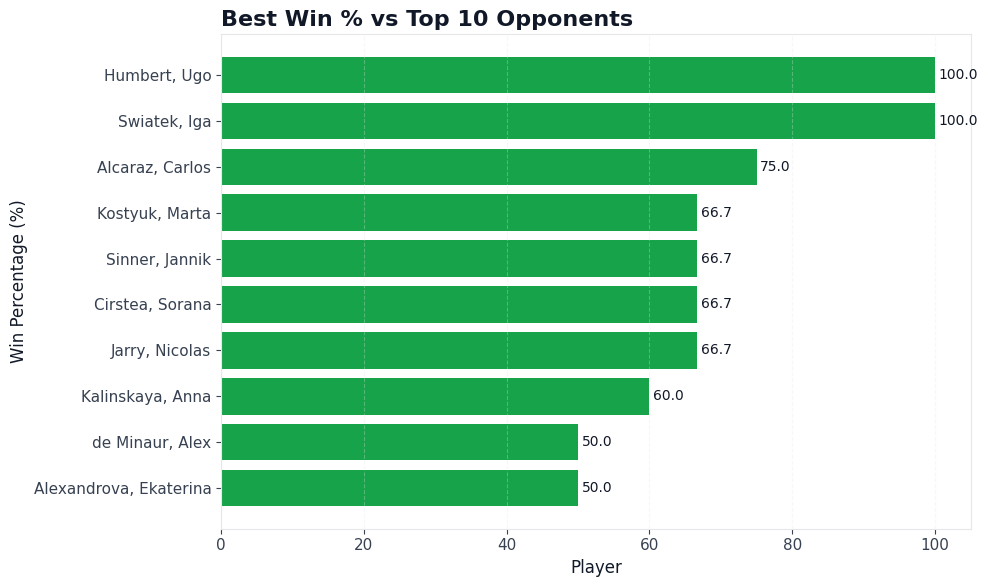


>> ANSWER Q16: Best player is Humbert, Ugo.


In [ ]:
matches_full = match_event_df[['match_id', 'winner_code']].copy()
matches_full = matches_full.merge(match_home_df[['match_id', 'full_name', 'current_rank']], on='match_id', suffixes=('', '_home'))
matches_full = matches_full.merge(match_away_df[['match_id', 'full_name', 'current_rank']], on='match_id', suffixes=('_home', '_away'))
matches_full.rename(columns={'full_name_home': 'home_player', 'current_rank_home': 'home_rank',
                             'full_name_away': 'away_player', 'current_rank_away': 'away_rank'}, inplace=True)

stats = {} 
for index, row in matches_full.iterrows():
    h_player, a_player = row['home_player'], row['away_player']
    h_rank, a_rank = row['home_rank'], row['away_rank']
    winner = row['winner_code']
    
    # Home vs Top 10 Away
    if not pd.isna(a_rank) and a_rank <= 10:
        if h_player not in stats: stats[h_player] = [0, 0]
        stats[h_player][1] += 1
        if winner == 1: stats[h_player][0] += 1
            
    # Away vs Top 10 Home
    if not pd.isna(h_rank) and h_rank <= 10:
        if a_player not in stats: stats[a_player] = [0, 0]
        stats[a_player][1] += 1
        if winner == 2: stats[a_player][0] += 1

perf_data = []
for p, v in stats.items():
    if v[1] >= 3: 
        perf_data.append({'Player': p, 'Wins': v[0], 'Total': v[1], 'Win_Pct': (v[0]/v[1])*100})

if perf_data:
    df_perf = pd.DataFrame(perf_data).sort_values(by='Win_Pct', ascending=False).head(10)
    
    print("Top Players by Win % vs Top 10 Opponents:")
    
    df_styled = df_perf.copy()
    df_styled['Win_Pct'] = df_styled['Win_Pct'].map('{:.1f}%'.format)
    display(df_styled) 
    
    
    plot_green_bar(df_perf['Player'], df_perf['Win_Pct'], 
                   title='Best Win % vs Top 10 Opponents', 
                   xlabel='Player', ylabel='Win Percentage (%)', 
                   orientation='horizontal', show_values=True) 
    
    print(f"\n>> ANSWER Q16: Best player is {df_perf.iloc[0]['Player']}.")
else:
    print("No sufficient data.")

## QUESTION 17: Average number of breaks of serve per match?

In [ ]:
# 1. load game info and identify servers
service_indicators = game_info_df[
    (game_info_df['home_point_type'].isin([1, 2, 3])) | 
    (game_info_df['away_point_type'].isin([1, 2, 3]))
].copy()
service_indicators['server'] = np.where(service_indicators['home_point_type'].isin([1, 2, 3]), 'home', 'away')
game_servers = service_indicators[['match_id', 'set_id', 'game_id', 'server']].drop_duplicates(subset=['match_id', 'set_id', 'game_id'])

# 2. Game
last_points = game_info_df.sort_values('point_id').groupby(['match_id', 'set_id', 'game_id']).tail(1)
break_analysis = last_points.merge(game_servers, on=['match_id', 'set_id', 'game_id'], how='inner')

break_analysis['game_winner'] = np.where(break_analysis['home_point_type'] != 0, 'home', 
                                         np.where(break_analysis['away_point_type'] != 0, 'away', 'unknown'))
break_analysis = break_analysis[break_analysis['game_winner'] != 'unknown']

# 3. Break determination
break_analysis['is_break'] = break_analysis['server'] != break_analysis['game_winner']

total_breaks_count = break_analysis['is_break'].sum()
analyzed_matches_count = break_analysis['match_id'].nunique()
avg_breaks = total_breaks_count / analyzed_matches_count if analyzed_matches_count > 0 else 0

# 4. Summary and output
df_q17 = pd.DataFrame({
    'Metric': ['Total Matches Analyzed', 'Total Breaks of Serve', 'Average Breaks per Match'],
    'Value': [f"{analyzed_matches_count}", f"{total_breaks_count}", f"{avg_breaks:.2f}"]
})

print("Summary of Breaks of Serve:")
display(df_q17) 

print(f"\n>> ANSWER Q17: Average breaks per match: {avg_breaks:.2f}")

Summary of Breaks of Serve:


,Metric,Value
0,Total Matches Analyzed,10956
1,Total Breaks of Serve,113151
2,Average Breaks per Match,10.33



>> ANSWER Q17: Average breaks per match: 10.33


## EXTRA QUESTIONS (1–8)

In [ ]:
# Shared styling helper (used in Extra Q1 & Extra Q2)
def set_modern_green_theme():
    plt.style.use("default")
    plt.rcParams.update({
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "axes.edgecolor": "#C8E6C9",
        "axes.labelcolor": "#1F2937",
        "xtick.color": "#374151",
        "ytick.color": "#374151",
        "text.color": "#111827",
        "font.size": 11,
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.labelsize": 12,
        "grid.color": "#E8F5E9",
        "grid.linestyle": "--",
        "grid.linewidth": 0.9,
        "grid.alpha": 1.0,
    })

### EXTRA QUESTION 1: Average double faults per match

Average double faults per match: 6.05
Number of matches analyzed: 11,389
Minimum double faults: 0
Maximum double faults: 36
Median: 5


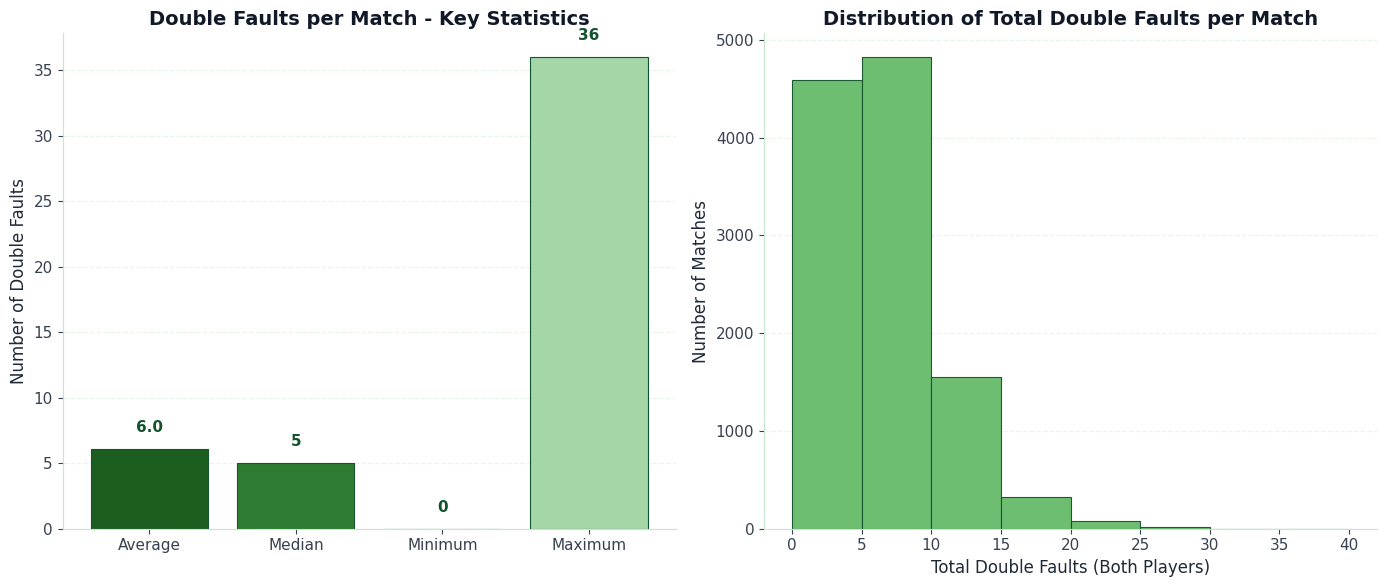

In [ ]:
# ---------- Modern White/Green Theme ----------
set_modern_green_theme()
# --------------------------------------------
df = PeriodInfo.copy()
double_faults = df[
    (df["statistic_name"] == "double_faults") &
    (df["period"] == "ALL")
].copy()

double_faults["home_df"] = pd.to_numeric(double_faults["home_value"], errors="coerce")
double_faults["away_df"] = pd.to_numeric(double_faults["away_value"], errors="coerce")
double_faults["total_df"] = double_faults["home_df"] + double_faults["away_df"]

double_faults = double_faults.dropna(subset=["total_df"]).copy()
double_faults["total_df"] = double_faults["total_df"].astype(int)

avg_df     = double_faults["total_df"].mean()
median_df  = double_faults["total_df"].median()
min_df     = double_faults["total_df"].min()
max_df     = double_faults["total_df"].max()
n_matches  = len(double_faults)

print(f"Average double faults per match: {avg_df:.2f}")
print(f"Number of matches analyzed: {n_matches:,}")
print(f"Minimum double faults: {int(min_df)}")
print(f"Maximum double faults: {int(max_df)}")
print(f"Median: {median_df:.0f}")

# ---------- SUMMARY BAR + HISTOGRAM ----------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig.patch.set_facecolor("white")

def modernize_ax(ax):
    ax.set_facecolor("white")
    ax.grid(axis="y", which="major")
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#C8E6C9")
    ax.spines["bottom"].set_color("#C8E6C9")

modernize_ax(ax1)
modernize_ax(ax2)

# Bar chart (green palette)
stats  = ["Average", "Median", "Minimum", "Maximum"]
values = [avg_df, median_df, min_df, max_df]
green_palette = ["#1B5E20", "#2E7D32", "#66BB6A", "#A5D6A7"]

bars = ax1.bar(stats, values, color=green_palette, edgecolor="#14532D", linewidth=0.8)
ax1.set_title("Double Faults per Match - Key Statistics")
ax1.set_ylabel("Number of Double Faults")

y_pad = max(values) * 0.03 if max(values) else 0.5
for bar in bars:
    h = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        h + y_pad,
        f"{h:.1f}" if h != int(h) else f"{int(h)}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color="#14532D",
    )

# Histogram
max_bin = int(max_df) + 5
bins = range(0, max_bin, 5)

ax2.hist(
    double_faults["total_df"],
    bins=bins,
    color="#66BB6A",
    edgecolor="#14532D",
    linewidth=0.8,
    alpha=0.95,
)
ax2.set_title("Distribution of Total Double Faults per Match")
ax2.set_xlabel("Total Double Faults (Both Players)")
ax2.set_ylabel("Number of Matches")

plt.tight_layout()
plt.show()

### EXTRA QUESTION 2: Tournament category with highest average tennis points

Highest average points: WTA (763.69 points)



,Average Points to Winner
tournament_category_name,
WTA,763.69
ATP,545.84
Challenger Women,125.00
Challenger,81.22


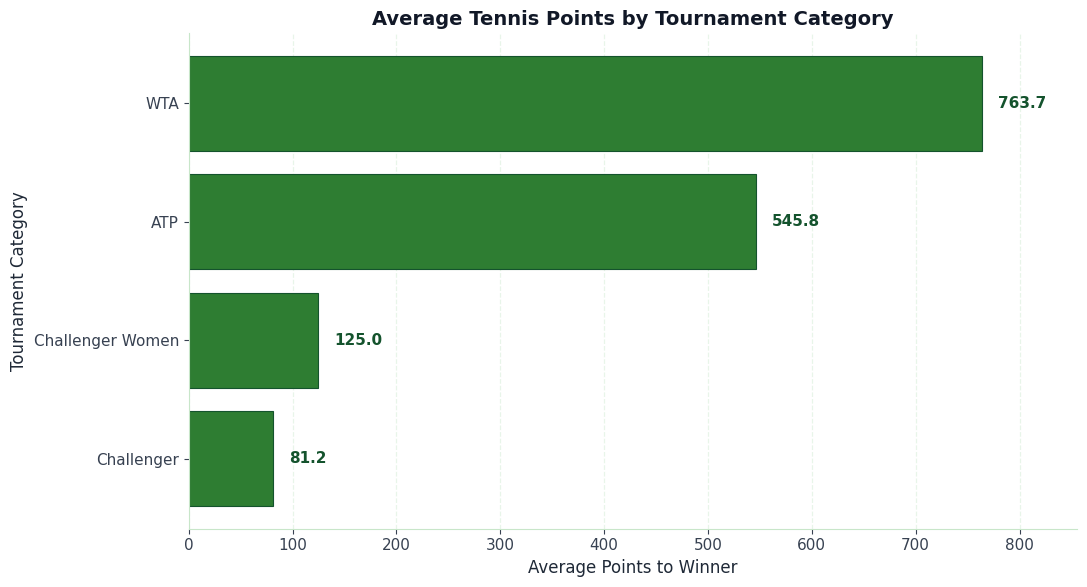

In [ ]:
set_modern_green_theme()
tourn = MatchTournamentInfo.copy()
tourn["tennis_points"] = pd.to_numeric(tourn["tennis_points"], errors="coerce")

avg_points = (
    tourn.groupby("tournament_category_name")["tennis_points"]
    .mean()
    .dropna()
    .sort_values(ascending=False)
)

highest_category = avg_points.index[0]
highest_avg = avg_points.iloc[0]
print(f"Highest average points: {highest_category} ({highest_avg:.2f} points)\n")

points_table = avg_points.to_frame(name="Average Points to Winner").round(2)
display(points_table)

fig, ax = plt.subplots(figsize=(11, 6))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

ax.grid(axis="x", which="major")
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#C8E6C9")
ax.spines["bottom"].set_color("#C8E6C9")

bars = ax.barh(
    avg_points.index,
    avg_points.values,
    color="#2E7D32",
    edgecolor="#14532D",
    linewidth=0.8,
)

ax.set_title("Average Tennis Points by Tournament Category")
ax.set_xlabel("Average Points to Winner")
ax.set_ylabel("Tournament Category")

max_val = float(avg_points.max()) if len(avg_points) else 0.0
x_pad = max_val * 0.02 if max_val else 0.5

for bar in bars:
    w = bar.get_width()
    ax.text(
        w + x_pad,
        bar.get_y() + bar.get_height() / 2,
        f"{w:.1f}",
        ha="left",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#14532D",
    )

ax.invert_yaxis()
ax.set_xlim(0, max_val * 1.12 if max_val else 1)

plt.tight_layout()
plt.show()

### EXTRA QUESTION 3: Court surface where players serve the most aces (average)

Surface source: MatchTournamentInfo.csv | Surface column: ground_type

ANSWER: Players serve the most aces on average on: Carpet indoor  (mean=5.55 aces/player, n=120)



,mean,median,n
surface,,,
Carpet indoor,5.55,5.00,120
Grass,4.63,3.75,156
Hardcourt indoor,3.92,3.00,2068
Hardcourt outdoor,2.73,2.00,5160
Red clay indoor,2.06,1.00,191
Green clay,2.06,1.50,18
Synthetic outdoor,1.62,1.00,78
Red clay,1.58,1.00,3445


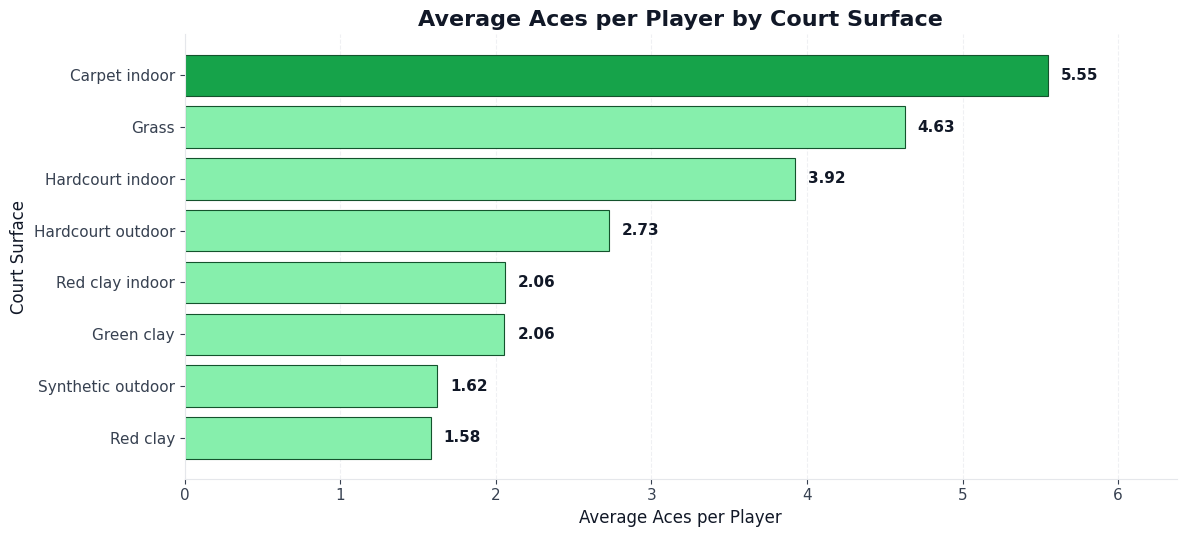

In [ ]:
# ---------- Theme ----------
def set_modern_neutral_theme():
    plt.style.use("default")
    plt.rcParams.update({
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "axes.edgecolor": "#E5E7EB",
        "axes.labelcolor": "#111827",
        "xtick.color": "#374151",
        "ytick.color": "#374151",
        "text.color": "#111827",
        "font.size": 11,
        "axes.titlesize": 16,
        "axes.titleweight": "bold",
        "axes.labelsize": 12,
        "grid.color": "#E5E7EB",
        "grid.linestyle": "--",
        "grid.linewidth": 0.8,
        "grid.alpha": 0.6,
    })

set_modern_neutral_theme()

def find_first_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

def find_surface_file_and_col(data_dir: Path):
    preferred_files = [
        "MatchInfo.csv",
        "MatchTournamentInfo.csv",
        "TournamentInfo.csv",
        "MatchSummaryInfo.csv",
        "MatchEventInfo.csv",
    ]

    def pick_surface_col(cols):
        cols_l = [c.lower() for c in cols]
        exact_priority = [
            "surface", "court_surface", "courtsurface",
            "surface_name", "court_surface_name", "ground", "ground_type"
        ]
        for key in exact_priority:
            for c, cl in zip(cols, cols_l):
                if cl == key:
                    return c
        for c, cl in zip(cols, cols_l):
            if "surface" in cl:
                return c
        for c, cl in zip(cols, cols_l):
            if "court" in cl and "type" in cl:
                return c
        return None

    for fn in preferred_files:
        fp = data_dir / fn
        if fp.exists():
            hdr = pd.read_csv(fp, nrows=0)
            s_col = pick_surface_col(hdr.columns)
            if s_col:
                return fp, s_col

    for fp in data_dir.glob("*.csv"):
        try:
            hdr = pd.read_csv(fp, nrows=0)
        except Exception:
            continue
        s_col = pick_surface_col(hdr.columns)
        if s_col:
            return fp, s_col

    raise FileNotFoundError(" not found DATA_DIR.")

# ---------- Load aces (PeriodInfo) ----------
period = PeriodInfo.copy()
match_id_col_p = find_first_col(period, ["match_id", "matchId", "id", "matchID"])
if not match_id_col_p:
    raise KeyError("match_id not found in PeriodInfo.")

aces = period[
    (period["statistic_name"].astype(str).str.lower() == "aces") &
    (period["period"].astype(str).str.upper() == "ALL")
].copy()

aces["home_aces"] = pd.to_numeric(aces["home_value"], errors="coerce")
aces["away_aces"] = pd.to_numeric(aces["away_value"], errors="coerce")
aces["total_aces"] = aces["home_aces"] + aces["away_aces"]
aces = aces.dropna(subset=["total_aces"])[[match_id_col_p, "total_aces"]].copy()

# ---------- Load surface + merge ----------
surface_file, surface_col = find_surface_file_and_col(DATA_DIR)
print("Surface source:", surface_file.name, "| Surface column:", surface_col)

surf = pd.read_csv(surface_file)
match_id_col_s = find_first_col(surf, ["match_id", "matchId", "id", "matchID"])
if not match_id_col_s:
    raise KeyError(f"match_id{surface_file.name} not found.")

surf = surf[[match_id_col_s, surface_col]].copy()
surf = surf.rename(columns={match_id_col_s: "match_id", surface_col: "surface"})
aces = aces.rename(columns={match_id_col_p: "match_id"})

merged = aces.merge(surf, on="match_id", how="inner")
merged["surface"] = merged["surface"].astype(str).str.strip()
merged = merged[merged["surface"].ne("") & merged["surface"].ne("nan")].copy()

# ---------- Metric: aces per player (average) ----------
merged["aces_per_player"] = merged["total_aces"] / 2.0

summary = (
    merged.groupby("surface")["aces_per_player"]
    .agg(mean="mean", median="median", n="count")
    .sort_values("mean", ascending=False)
)

best_surface = summary.index[0]
best_mean = float(summary.iloc[0]["mean"])
best_n = int(summary.iloc[0]["n"])

print(f"\nANSWER: Players serve the most aces on average on: {best_surface}  (mean={best_mean:.2f} aces/player, n={best_n})\n")
display(summary.round({"mean": 2, "median": 2}))

# ---------- Plot ----------
plot_df = summary.copy()
labels = [f"{s}" for s, n in zip(plot_df.index, plot_df["n"])]

fig_h = max(5.5, 0.5 * len(plot_df))
fig, ax = plt.subplots(figsize=(12, fig_h))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

ax.grid(axis="x")
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

highlight = "#16A34A"
muted = "#86EFAC"
edge = "#14532D"
colors = [highlight] + [muted] * (len(plot_df) - 1)

bars = ax.barh(labels, plot_df["mean"].values, color=colors, edgecolor=edge, linewidth=0.8)
ax.invert_yaxis()

ax.set_title("Average Aces per Player by Court Surface")
ax.set_xlabel("Average Aces per Player")
ax.set_ylabel("Court Surface")

mx = float(plot_df["mean"].max()) if len(plot_df) else 0.0
pad = mx * 0.015 if mx else 0.2

for bar, val in zip(bars, plot_df["mean"].values):
    ax.text(bar.get_width() + pad,
            bar.get_y() + bar.get_height()/2,
            f"{val:.2f}",
            va="center", ha="left",
            fontsize=11, fontweight="bold")

ax.set_xlim(0, mx * 1.15 if mx else 1)
plt.tight_layout()
plt.show()

### EXTRA QUESTION 4: Average first serve percentage per match (and by gender)

Gender source: MatchHomeTeamInfo.csv + MatchAwayTeamInfo.csv | columns: gender / gender

Average 1st-serve points won % per match: 27.87% (median=26.50%, n=8,947)



,mean,median,std,n
match_gender,,,,
F,26.17,25.0,9.63,3938
M,29.21,28.0,10.47,5009


Difference (M - F): 3.04 percentage points

In the tennis dataset covering 8,947 matches, players win an average of 27.87% of points on their first serve (median 26.50%). This metric reflects how effective the first-serve phase is: once the first serve lands, how often the server converts that point into a win.

By gender, men’s matches average 29.21% (median 28.00%, n=5,009), while women’s matches average 26.17% (median 25.00%, n=3,938). The mean gap is 3.04 percentage points (M − F). Overall, the results suggest that first-serve point outcomes do differ by gender in this dataset, though the size of the gap should be interpreted as a descriptive difference rather than causation.



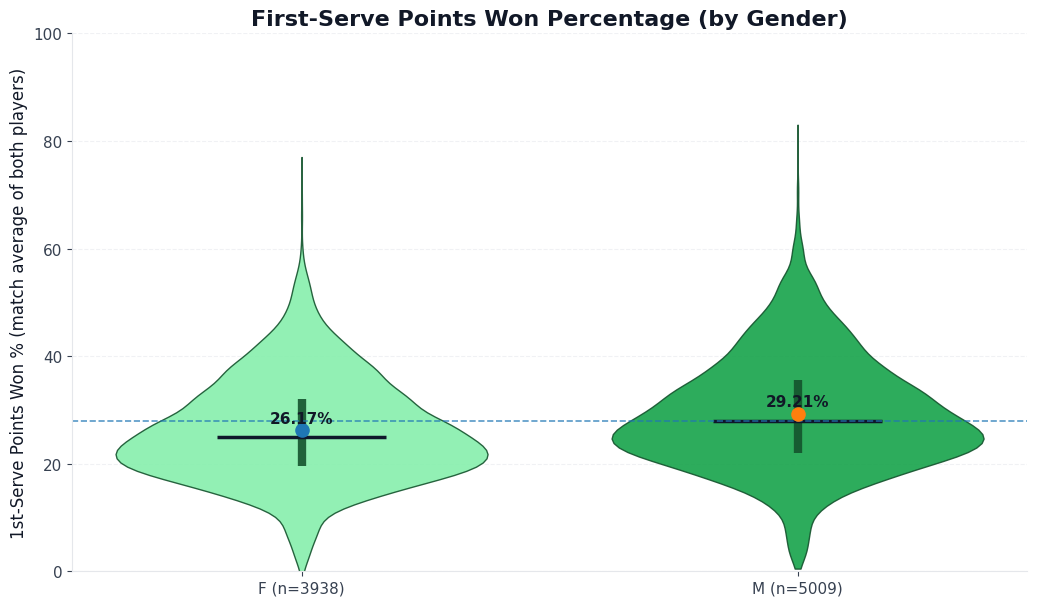

In [ ]:
def set_theme():
    plt.style.use("default")
    plt.rcParams.update({
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "axes.edgecolor": "#E5E7EB",
        "axes.labelcolor": "#111827",
        "xtick.color": "#374151",
        "ytick.color": "#374151",
        "text.color": "#111827",
        "font.size": 11,
        "axes.titlesize": 16,
        "axes.titleweight": "bold",
        "axes.labelsize": 12,
        "grid.color": "#E5E7EB",
        "grid.linestyle": "--",
        "grid.linewidth": 0.8,
        "grid.alpha": 0.55,
    })

set_theme()

def first_existing_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

def normalize_gender(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if s in {"m", "male", "men", "man"} or s.startswith("m"):
        return "M"
    if s in {"f", "female", "women", "woman"} or s.startswith("f"):
        return "F"
    return np.nan

def parse_pct_or_ratio(v):
    if pd.isna(v):
        return np.nan
    s = str(v).strip()
    if not s:
        return np.nan
    s = s.replace("%", "").strip()

    # format like "34/50"
    if "/" in s:
        parts = s.split("/")
        if len(parts) == 2:
            a = pd.to_numeric(parts[0].strip(), errors="coerce")
            b = pd.to_numeric(parts[1].strip(), errors="coerce")
            if pd.notna(a) and pd.notna(b) and b > 0:
                return float(a) / float(b) * 100.0
        return np.nan

    x = pd.to_numeric(s, errors="coerce")
    if pd.isna(x):
        return np.nan
    return float(x)

def find_gender_source(data_dir: Path):
    preferred = ["MatchInfo.csv", "MatchEventInfo.csv", "MatchTournamentInfo.csv", "MatchSummaryInfo.csv"]
    for fn in preferred:
        fp = data_dir / fn
        if fp.exists():
            hdr = pd.read_csv(fp, nrows=0)
            mid = first_existing_col(hdr, ["match_id", "matchId", "id", "matchID"])
            gcol = None
            for c in hdr.columns:
                cl = str(c).strip().lower()
                if cl in {"match_gender", "gender"}:
                    gcol = c
                    break
            if not gcol:
                for c in hdr.columns:
                    if "gender" in str(c).strip().lower():
                        gcol = c
                        break
            if mid and gcol:
                return ("match_level", fp, mid, gcol)

    home_fp = data_dir / "MatchHomeTeamInfo.csv"
    away_fp = data_dir / "MatchAwayTeamInfo.csv"
    if home_fp.exists() and away_fp.exists():
        hh = pd.read_csv(home_fp, nrows=0)
        ah = pd.read_csv(away_fp, nrows=0)
        hmid = first_existing_col(hh, ["match_id", "matchId", "id", "matchID"])
        amid = first_existing_col(ah, ["match_id", "matchId", "id", "matchID"])
        hg = first_existing_col(hh, ["gender"])
        ag = first_existing_col(ah, ["gender"])
        if hmid and amid and hg and ag:
            return ("team_level", (home_fp, away_fp), (hmid, amid), (hg, ag))

    raise FileNotFoundError("No usable gender source found.")

# ================== LOAD PERIOD ==================
period = PeriodInfo.copy()
match_id_col = first_existing_col(period, ["match_id", "matchId", "id", "matchID"])
if not match_id_col:
    raise KeyError("Match id column not found in PeriodInfo.csv")

period_all = period[period["period"].astype(str).str.upper() == "ALL"].copy()

# ================== FIRST SERVE POINTS WON % ==================
stat = "first_serve_points"
fs = period_all[period_all["statistic_name"].astype(str).str.strip().str.lower() == stat].copy()
if fs.empty:
    raise ValueError("No rows for statistic_name='first_serve_points' with period=ALL.")

fs["home_pct"] = fs["home_value"].map(parse_pct_or_ratio)
fs["away_pct"] = fs["away_value"].map(parse_pct_or_ratio)
fs = fs.dropna(subset=["home_pct", "away_pct"]).copy()

mx = max(fs["home_pct"].max(), fs["away_pct"].max())
if mx <= 1.5:
    fs["home_pct"] *= 100
    fs["away_pct"] *= 100

fs["match_first_serve_points_won_pct"] = (fs["home_pct"] + fs["away_pct"]) / 2.0
fs_match = fs[[match_id_col, "match_first_serve_points_won_pct"]].rename(columns={match_id_col: "match_id"}).copy()

# keep plausible range
fs_match = fs_match[(fs_match["match_first_serve_points_won_pct"] >= 0) & (fs_match["match_first_serve_points_won_pct"] <= 100)].copy()

# ================== GENDER JOIN ==================
src = find_gender_source(DATA_DIR)

if src[0] == "match_level":
    _, fp, mid, gcol = src
    print("Gender source:", fp.name, "| column:", gcol)
    gdf = pd.read_csv(fp)[[mid, gcol]].rename(columns={mid: "match_id", gcol: "match_gender"}).copy()
    gdf["match_gender"] = gdf["match_gender"].apply(normalize_gender)
    merged = fs_match.merge(gdf, on="match_id", how="inner")
else:
    _, (home_fp, away_fp), (hmid, amid), (hg, ag) = src
    print("Gender source:", home_fp.name, "+", away_fp.name, "| columns:", hg, "/", ag)

    home = pd.read_csv(home_fp)[[hmid, hg]].rename(columns={hmid: "match_id", hg: "home_gender"}).copy()
    away = pd.read_csv(away_fp)[[amid, ag]].rename(columns={amid: "match_id", ag: "away_gender"}).copy()

    home["home_gender"] = home["home_gender"].apply(normalize_gender)
    away["away_gender"] = away["away_gender"].apply(normalize_gender)

    gdf = home.merge(away, on="match_id", how="inner").dropna(subset=["home_gender", "away_gender"]).copy()
    gdf = gdf[gdf["home_gender"] == gdf["away_gender"]].copy()
    gdf["match_gender"] = gdf["home_gender"]
    gdf = gdf[["match_id", "match_gender"]].copy()

    merged = fs_match.merge(gdf, on="match_id", how="inner")

merged = merged.dropna(subset=["match_gender", "match_first_serve_points_won_pct"]).copy()

# ================== SUMMARY ==================
overall_mean = float(merged["match_first_serve_points_won_pct"].mean())
overall_median = float(merged["match_first_serve_points_won_pct"].median())
n_all = int(len(merged))

by_gender = (
    merged.groupby("match_gender")["match_first_serve_points_won_pct"]
    .agg(mean="mean", median="median", std="std", n="count")
    .sort_index()
)

print(f"\nAverage 1st-serve points won % per match: {overall_mean:.2f}% (median={overall_median:.2f}%, n={n_all:,})\n")
display(by_gender.round({"mean": 2, "median": 2, "std": 2}))

m_mean = float(by_gender.loc["M", "mean"]) if "M" in by_gender.index else np.nan
f_mean = float(by_gender.loc["F", "mean"]) if "F" in by_gender.index else np.nan
diff = (m_mean - f_mean) if (pd.notna(m_mean) and pd.notna(f_mean)) else np.nan
if pd.notna(diff):
    print(f"Difference (M - F): {diff:.2f} percentage points")

# ================== REPORT (ENGLISH) ==================
m_n = int(by_gender.loc["M", "n"]) if "M" in by_gender.index else 0
f_n = int(by_gender.loc["F", "n"]) if "F" in by_gender.index else 0
m_med = float(by_gender.loc["M", "median"]) if "M" in by_gender.index else np.nan
f_med = float(by_gender.loc["F", "median"]) if "F" in by_gender.index else np.nan

report = (
    f"In the tennis dataset covering {n_all:,} matches, players win an average of "
    f"{overall_mean:.2f}% of points on their first serve (median {overall_median:.2f}%). "
    f"This metric reflects how effective the first-serve phase is: once the first serve lands, "
    f"how often the server converts that point into a win.\n\n"
)

if pd.notna(m_mean) and pd.notna(f_mean):
    report += (
        f"By gender, men’s matches average {m_mean:.2f}% (median {m_med:.2f}%, n={m_n:,}), "
        f"while women’s matches average {f_mean:.2f}% (median {f_med:.2f}%, n={f_n:,}). "
        f"The mean gap is {diff:.2f} percentage points (M − F). "
        f"Overall, the results suggest that first-serve point outcomes do differ by gender in this dataset, "
        f"though the size of the gap should be interpreted as a descriptive difference rather than causation."
    )
else:
    report += "Gender breakdown could not be computed due to missing/insufficient gender data."

print("\n" + report + "\n")

# ================== PLOT (Nicer) ==================
order = [g for g in ["F", "M"] if g in by_gender.index]
data = [merged.loc[merged["match_gender"] == g, "match_first_serve_points_won_pct"].values for g in order]
labels = [f"{g} (n={int(by_gender.loc[g,'n'])})" for g in order]

fig, ax = plt.subplots(figsize=(10.5, 6.2))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

ax.grid(axis="y")
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

vp = ax.violinplot(data, showmeans=False, showmedians=False, showextrema=False, widths=0.75)

fills = ["#86EFAC", "#16A34A"][:len(order)]
edge = "#14532D"

for body, c in zip(vp["bodies"], fills):
    body.set_facecolor(c)
    body.set_edgecolor(edge)
    body.set_alpha(0.9)
    body.set_linewidth(1.0)

# quartiles + median + mean
for i, arr in enumerate(data, start=1):
    q1, med, q3 = np.percentile(arr, [25, 50, 75])
    mu = float(np.mean(arr))
    ax.vlines(i, q1, q3, color=edge, linewidth=6, alpha=0.9)
    ax.scatter([i], [mu], s=90, zorder=3)
    ax.hlines(med, i - 0.17, i + 0.17, color="#0F172A", linewidth=2.5)
    ax.text(i, mu + 0.9, f"{mu:.2f}%", ha="center", va="bottom", fontsize=11, fontweight="bold")

ax.axhline(overall_mean, linestyle="--", linewidth=1.2, alpha=0.75)
ax.set_title("First-Serve Points Won Percentage (by Gender)")
ax.set_ylabel("1st-Serve Points Won % (match average of both players)")
ax.set_xticks(range(1, len(labels) + 1))
ax.set_xticklabels(labels)
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

### EXTRA QUESTION 5: Do more aces associate with winning the match?

Do more aces associate with winning the MATCH? (Association, not causation)
Matches joined: 10,510
Non-tie aces matches: 8,084 | Aces ties: 2,426
Win rate of the side with MORE aces (excluding ties): 64.88%


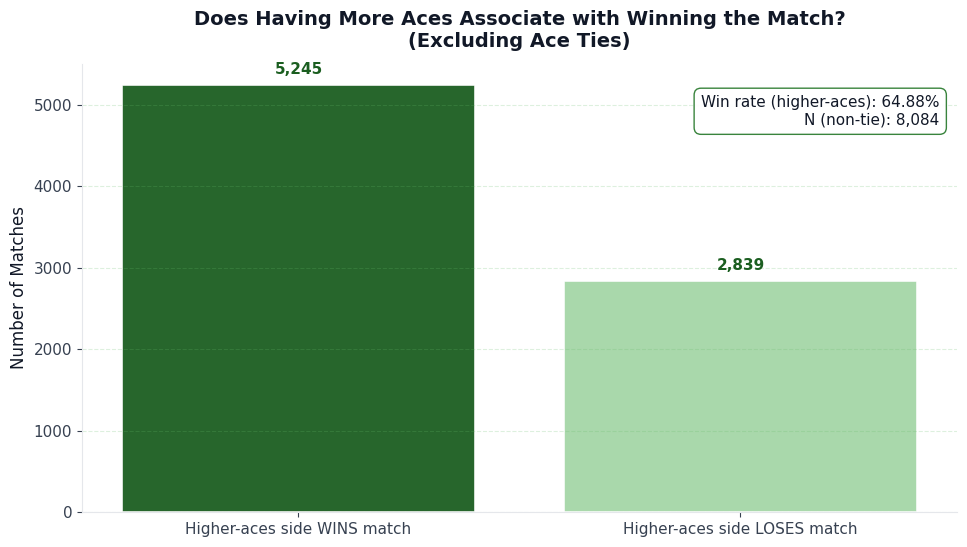

C:\Users\ASUS\AppData\Local\Temp\ipykernel_1608\2120398383.py:126: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bucket = df2.groupby("ace_diff_bin").agg(


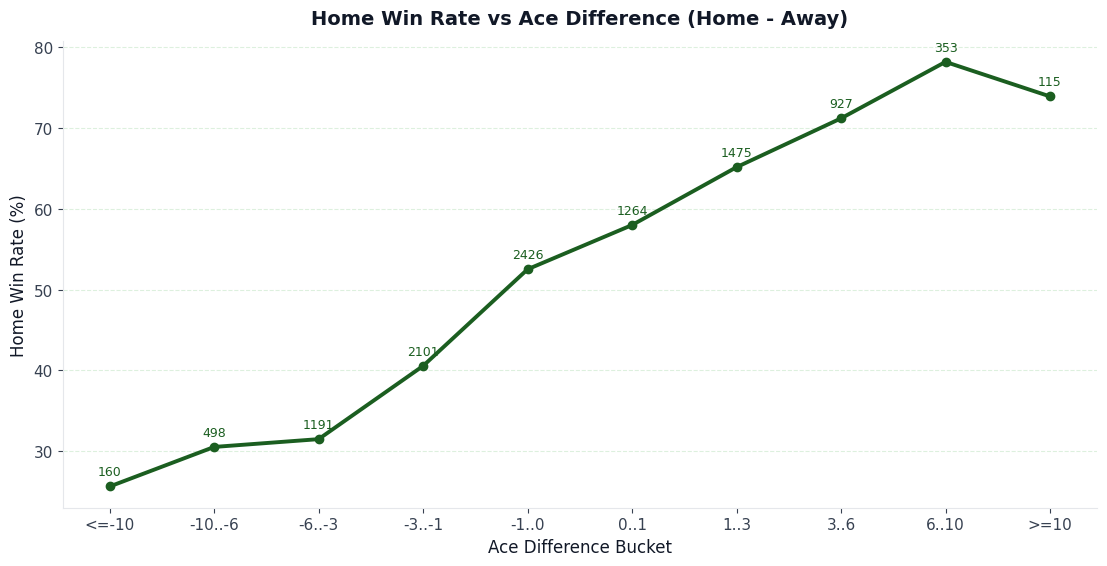

In [ ]:
# =========================
# Q: Do more aces associate with winning the MATCH?
# Data:
# - PeriodInfo (aces)  period=ALL, category=Service(s), name=aces
# - MatchEventInfo (winner_code)  1=Home, 2=Away
# =========================

# ---------- 1) Aces per match ----------

pi = PeriodInfo.copy()

mask = (
    pi["period"].astype(str).str.strip().str.upper().eq("ALL")
    & pi["statistic_category_name"].astype(str).str.strip().str.lower().isin(["service", "services"])
    & pi["statistic_name"].astype(str).str.strip().str.lower().eq("aces")
)

aces_rows = pi.loc[mask].copy()
if aces_rows.empty:
    raise ValueError("No rows found for: period=ALL, statistic_category_name=Service(s), statistic_name=aces")

def pick_numeric(df, cols):
    for c in cols:
        if c in df.columns:
            s = pd.to_numeric(df[c], errors="coerce")
            if s.notna().any():
                return s
    return pd.Series([np.nan] * len(df), index=df.index)

aces_rows["home_aces"] = pick_numeric(aces_rows, ["home_value", "home_total", "home_stat"])
aces_rows["away_aces"] = pick_numeric(aces_rows, ["away_value", "away_total", "away_stat"])

aces_by_match = (
    aces_rows.groupby("match_id", as_index=False)[["home_aces", "away_aces"]]
    .sum(min_count=1)
)

aces_by_match["ace_diff"] = aces_by_match["home_aces"] - aces_by_match["away_aces"]
aces_by_match["ace_more_side"] = np.where(
    aces_by_match["ace_diff"] > 0, 1,
    np.where(aces_by_match["ace_diff"] < 0, 2, 0)  # 0 means tie
)

# ---------- 2) Match results from MatchEventInfo ----------

match_results = (
    MatchEventInfo[["match_id", "winner_code"]]
    .dropna()
    .copy()
)

match_results["winner_code"] = pd.to_numeric(match_results["winner_code"], errors="coerce")
match_results = match_results[match_results["winner_code"].isin([1, 2])]

# ---------- 3) Join + metrics ----------
df = aces_by_match.merge(match_results, on="match_id", how="inner")
df = df.dropna(subset=["home_aces", "away_aces", "winner_code"])

if df.empty:
    raise ValueError("No rows after joining aces and match results. Check match_id consistency.")

df["is_tie_aces"] = df["ace_more_side"].eq(0)
df["higher_aces_won_match"] = (df["ace_more_side"] == df["winner_code"]) & (~df["is_tie_aces"])

non_tie = df[~df["is_tie_aces"]].copy()

# Win rate when one side has more aces
win_rate = float(non_tie["higher_aces_won_match"].mean()) if len(non_tie) else np.nan

wins = int(non_tie["higher_aces_won_match"].sum()) if len(non_tie) else 0
losses = int(len(non_tie) - wins) if len(non_tie) else 0
ties = int(df["is_tie_aces"].sum())

print("Do more aces associate with winning the MATCH? (Association, not causation)")
print(f"Matches joined: {len(df):,}")
print(f"Non-tie aces matches: {len(non_tie):,} | Aces ties: {ties:,}")
if not np.isnan(win_rate):
    print(f"Win rate of the side with MORE aces (excluding ties): {win_rate*100:.2f}%")
else:
    print("Not enough non-tie matches to compute win rate.")

# ---------- 4) Chart 1: Win vs Lose for higher-aces side ----------
if len(non_tie) > 0:
    fig, ax = plt.subplots(figsize=(9.8, 5.6), facecolor="white")
    ax.set_facecolor("white")

    labels = ["Higher-aces side WINS match", "Higher-aces side LOSES match"]
    vals = [wins, losses]
    bars = ax.bar(labels, vals, color=["#1b5e20", "#a5d6a7"], edgecolor="white", linewidth=1.2, alpha=0.95)

    ax.set_title("Does Having More Aces Associate with Winning the Match?\n(Excluding Ace Ties)",
                 pad=12, fontsize=14, fontweight="bold")
    ax.set_ylabel("Number of Matches")
    ax.grid(axis="y", linestyle="--", alpha=0.22, color="#66bb6a")
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    ymax = max(vals)
    offset = max(1, int(ymax * 0.02))

    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, v + offset, f"{v:,}",
                ha="center", va="bottom", fontsize=11, color="#1b5e20", fontweight="bold")

    ax.text(
        0.98, 0.93,
        f"Win rate (higher-aces): {win_rate*100:.2f}%\nN (non-tie): {len(non_tie):,}",
        transform=ax.transAxes,
        ha="right", va="top",
        fontsize=11,
        bbox=dict(boxstyle="round,pad=0.45", facecolor="white", edgecolor="#2e7d32", alpha=0.95)
    )

    plt.tight_layout()
    plt.show()

# ---------- 5) Chart 2: Home win rate vs ace_diff buckets ----------
df2 = df.copy()
df2["home_win"] = df2["winner_code"].eq(1)

bins = [-999, -10, -6, -3, -1, 0, 1, 3, 6, 10, 999]
bin_labels = ["<=-10","-10..-6","-6..-3","-3..-1","-1..0","0..1","1..3","3..6","6..10",">=10"]

df2["ace_diff_bin"] = pd.cut(df2["ace_diff"], bins=bins, labels=bin_labels, include_lowest=True)

bucket = df2.groupby("ace_diff_bin").agg(
    n=("match_id", "size"),
    home_win_rate=("home_win", "mean")
).reset_index()

fig, ax = plt.subplots(figsize=(11.2, 5.8), facecolor="white")
ax.set_facecolor("white")

x = np.arange(len(bucket))
y = (bucket["home_win_rate"] * 100).to_numpy()

ax.plot(x, y, marker="o", linewidth=2.8, color="#1b5e20")

ax.set_xticks(x)
ax.set_xticklabels(bucket["ace_diff_bin"].astype(str), rotation=0)

ax.set_title("Home Win Rate vs Ace Difference (Home - Away)", pad=12, fontsize=14, fontweight="bold")
ax.set_xlabel("Ace Difference Bucket")
ax.set_ylabel("Home Win Rate (%)")
ax.grid(axis="y", linestyle="--", alpha=0.22, color="#66bb6a")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

for i, (pct, n) in enumerate(zip(y, bucket["n"].to_numpy())):
    if not np.isnan(pct):
        ax.text(i, pct + 1.0, f"{int(n)}", ha="center", va="bottom", fontsize=9, color="#1b5e20")

plt.tight_layout()
plt.show()

After excluding matches where aces were tied, we analyzed 8,084 matches and found that the side with more aces won 64.88% of the time. This indicates a clear positive association between serving more aces and winning the match in this dataset. However, this result reflects correlation rather than causation—players who are stronger overall may both serve more aces and win more often.

### EXTRA QUESTION 6: More double faults == more match losses?

More double faults == more match LOSSES? (Association, not causation)
Matches joined: 10,510
Non-tie (double faults): 8,735 | Ties: 1,775
Loss rate of the side with MORE double faults (excluding ties): 62.51%


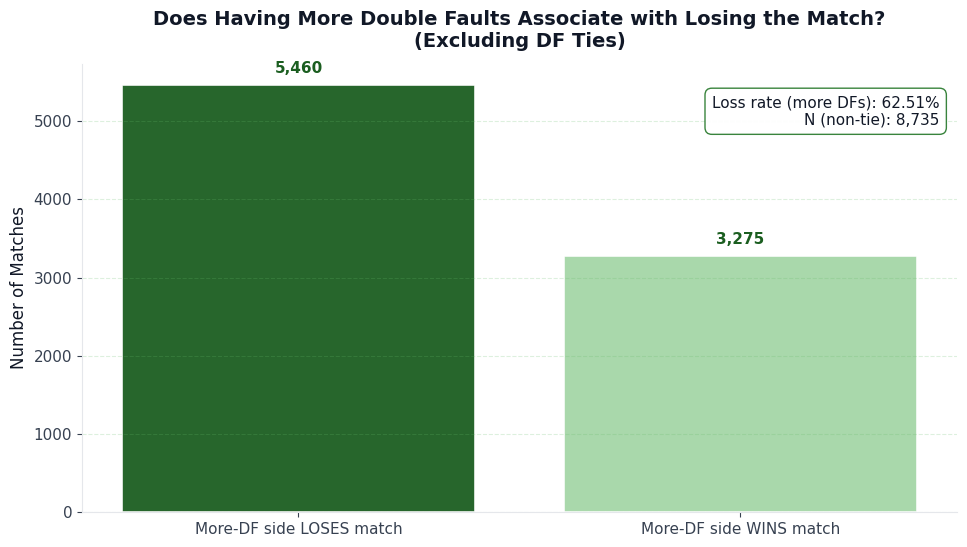

C:\Users\ASUS\AppData\Local\Temp\ipykernel_1608\732861977.py:131: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bucket = df2.groupby("df_diff_bin").agg(


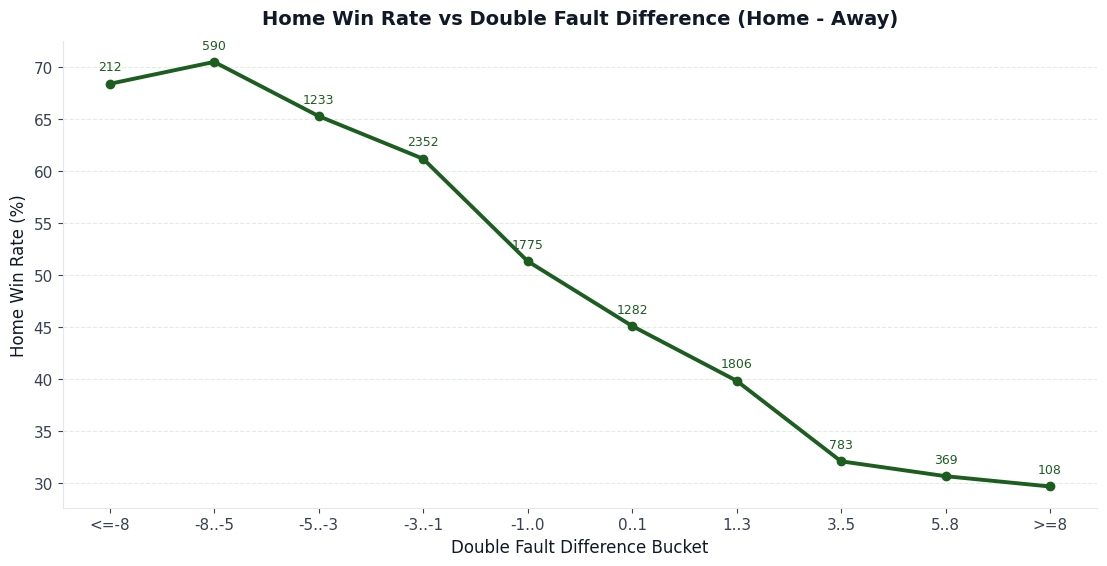

In [ ]:
# =========================
# More double faults == more match losses? (Association test)
# Requires:
#   PeriodInfo (DataFrame)
#   MatchEventInfo (DataFrame) with columns: match_id, winner_code (1=Home, 2=Away)
# =========================

# ---------- 1) Extract DOUBLE FAULTS per match from PeriodInfo ----------

pi = PeriodInfo.copy()

# flexible matching for statistic_category_name and statistic_name
cat_ok = pi["statistic_category_name"].astype(str).str.strip().str.lower().str.contains("service")
name_norm = pi["statistic_name"].astype(str).str.strip().str.lower()

# common variants: "double faults", "double_faults", "double fault", "doublefaults"
df_ok = name_norm.isin(["double faults", "double fault", "double_faults", "doublefaults", "double-faults", "double-fault"])

mask = (
    pi["period"].astype(str).str.strip().str.upper().eq("ALL")
    & cat_ok
    & df_ok
)

df_rows = pi.loc[mask].copy()
if df_rows.empty:
    raise ValueError(
        "No rows found for Double Faults with filters:\n"
        "- period = ALL\n- statistic_category_name contains 'service'\n"
        "- statistic_name in {double faults, double fault, double_faults, ...}\n"
        "Tip: check unique PeriodInfo['statistic_name'] values."
    )

def pick_numeric(df, cols):
    for c in cols:
        if c in df.columns:
            s = pd.to_numeric(df[c], errors="coerce")
            if s.notna().any():
                return s
    return pd.Series([np.nan] * len(df), index=df.index)

df_rows["home_df"] = pick_numeric(df_rows, ["home_value", "home_total", "home_stat"])
df_rows["away_df"] = pick_numeric(df_rows, ["away_value", "away_total", "away_stat"])

df_by_match = (
    df_rows.groupby("match_id", as_index=False)[["home_df", "away_df"]]
    .sum(min_count=1)
)
df_by_match["df_diff"] = df_by_match["home_df"] - df_by_match["away_df"]  # (+) means Home made more DFs
df_by_match["df_more_side"] = np.where(
    df_by_match["df_diff"] > 0, 1,
    np.where(df_by_match["df_diff"] < 0, 2, 0)  # 0 means tie
)

# ---------- 2) Match results from MatchEventInfo ----------
match_results = MatchEventInfo[["match_id", "winner_code"]].dropna().copy()
match_results["winner_code"] = pd.to_numeric(match_results["winner_code"], errors="coerce")
match_results = match_results[match_results["winner_code"].isin([1, 2])]

# ---------- 3) Join + metrics ----------
df = df_by_match.merge(match_results, on="match_id", how="inner").dropna(subset=["home_df", "away_df", "winner_code"])
if df.empty:
    raise ValueError("No rows after joining double faults and match results. Check match_id consistency.")

df["is_tie_df"] = df["df_more_side"].eq(0)

# Side with MORE double faults lost?
# If df_more_side is the winner => it did NOT lose; otherwise it lost.
df["more_df_side_lost"] = (df["df_more_side"] != df["winner_code"]) & (~df["is_tie_df"])

non_tie = df[~df["is_tie_df"]].copy()

loss_rate = float(non_tie["more_df_side_lost"].mean()) if len(non_tie) else np.nan
wins = int((~non_tie["more_df_side_lost"]).sum()) if len(non_tie) else 0
losses = int(non_tie["more_df_side_lost"].sum()) if len(non_tie) else 0
ties = int(df["is_tie_df"].sum())

print("More double faults == more match LOSSES? (Association, not causation)")
print(f"Matches joined: {len(df):,}")
print(f"Non-tie (double faults): {len(non_tie):,} | Ties: {ties:,}")
if not np.isnan(loss_rate):
    print(f"Loss rate of the side with MORE double faults (excluding ties): {loss_rate*100:.2f}%")
else:
    print("Not enough non-tie matches to compute loss rate.")

# ---------- 4) Chart 1 — more-DF side loses vs wins ----------
if len(non_tie) > 0:
    fig, ax = plt.subplots(figsize=(9.8, 5.6), facecolor="white")
    ax.set_facecolor("white")

    labels = ["More-DF side LOSES match", "More-DF side WINS match"]
    vals = [losses, wins]
    bars = ax.bar(labels, vals, color=["#1b5e20", "#a5d6a7"], edgecolor="white", linewidth=1.2, alpha=0.95)

    ax.set_title("Does Having More Double Faults Associate with Losing the Match?\n(Excluding DF Ties)",
                 pad=12, fontsize=14, fontweight="bold")
    ax.set_ylabel("Number of Matches")
    ax.grid(axis="y", linestyle="--", alpha=0.22, color="#66bb6a")
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    ymax = max(vals)
    offset = max(1, int(ymax * 0.02))

    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, v + offset, f"{v:,}",
                ha="center", va="bottom", fontsize=11, color="#1b5e20", fontweight="bold")

    ax.text(
        0.98, 0.93,
        f"Loss rate (more DFs): {loss_rate*100:.2f}%\nN (non-tie): {len(non_tie):,}",
        transform=ax.transAxes,
        ha="right", va="top",
        fontsize=11,
        bbox=dict(boxstyle="round,pad=0.45", facecolor="white", edgecolor="#2e7d32", alpha=0.95)
    )

    plt.tight_layout()
    plt.show()

# ---------- 5) Chart 2 — Home win rate vs df_diff buckets  ----------
# Interpretable: if df_diff is positive (Home made more DFs), Home win rate should drop.
df2 = df.copy()
df2["home_win"] = df2["winner_code"].eq(1)

bins = [-999, -8, -5, -3, -1, 0, 1, 3, 5, 8, 999]
bin_labels = ["<=-8","-8..-5","-5..-3","-3..-1","-1..0","0..1","1..3","3..5","5..8",">=8"]

df2["df_diff_bin"] = pd.cut(df2["df_diff"], bins=bins, labels=bin_labels, include_lowest=True)

bucket = df2.groupby("df_diff_bin").agg(
    n=("match_id", "size"),
    home_win_rate=("home_win", "mean")
).reset_index()

fig, ax = plt.subplots(figsize=(11.2, 5.8), facecolor="white")
ax.set_facecolor("white")

x = np.arange(len(bucket))
y = (bucket["home_win_rate"] * 100).to_numpy()

ax.plot(x, y, marker="o", linewidth=2.8, color="#1b5e20")

ax.set_xticks(x)
ax.set_xticklabels(bucket["df_diff_bin"].astype(str), rotation=0)

ax.set_title("Home Win Rate vs Double Fault Difference (Home - Away)", pad=12, fontsize=14, fontweight="bold")
ax.set_xlabel("Double Fault Difference Bucket")
ax.set_ylabel("Home Win Rate (%)")
ax.grid(axis="y", linestyle="--", alpha=0.22, color="#66bb6a")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

for i, (pct, n) in enumerate(zip(y, bucket["n"].to_numpy())):
    if not np.isnan(pct):
        ax.text(i, pct + 1.0, f"{int(n)}", ha="center", va="bottom", fontsize=9, color="#1b5e20")

plt.tight_layout()
plt.show()

In this dataset, we compared match outcomes against double-fault counts and excluded matches where both sides recorded the same number of double faults. Across 8,735 non-tied matches, the side with more double faults lost 62.51% of the time. This shows a strong negative association between committing more double faults and winning the match—players who double fault more frequently are substantially more likely to lose. As with any observational result, this reflects association rather than direct causation, since overall player strength and match context can influence both double faults and match outcomes.

### EXTRA QUESTION 7: Breaks (service turns) and win-related metrics

Does service turn lead to more game wins? (Using break_occurred)
Total games analyzed: 10,987
Hold (server wins): 7,749 (70.53%)
Break (server loses): 3,238 (29.47%)


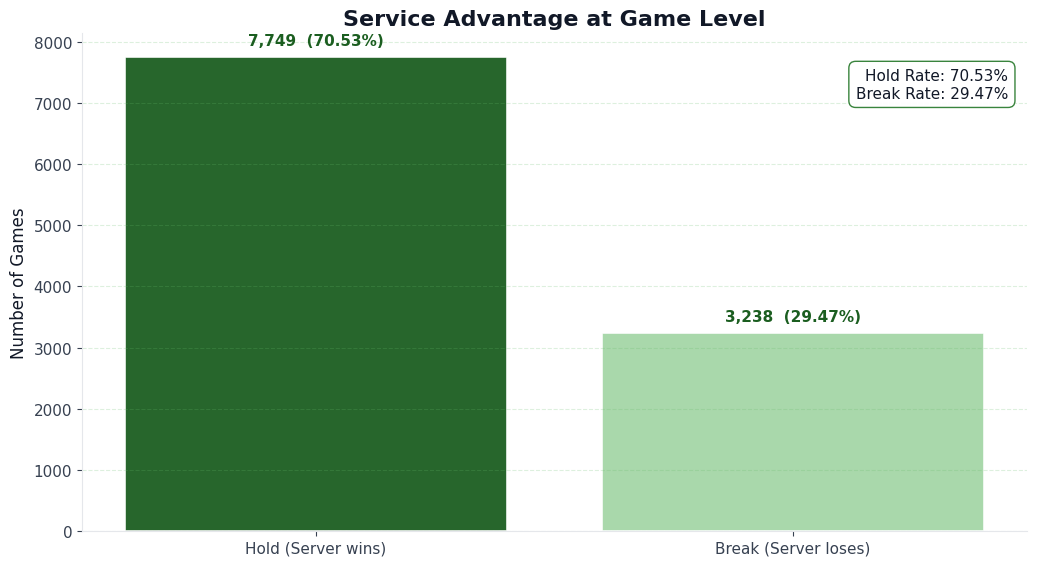

In [ ]:
if 'PowerInfo' not in globals() or PowerInfo is None:
    PowerInfo_path, PowerInfo = load_csv('PowerInfo.csv')

# --- Load ---

# --- Clean ---
pi = PowerInfo.copy()

if "break_occurred" not in pi.columns:
    raise ValueError("PowerInfo must contain 'break_occurred' column.")

def to_bool(x):
    if pd.isna(x):
        return np.nan
    if isinstance(x, bool):
        return x
    s = str(x).strip().lower()
    if s in ["true", "1", "t", "yes", "y"]:
        return True
    if s in ["false", "0", "f", "no", "n"]:
        return False
    return np.nan

pi["break_bool"] = pi["break_occurred"].apply(to_bool)
pi_clean = pi.dropna(subset=["break_bool"]).copy()

if pi_clean.empty:
    raise ValueError("No valid break_occurred values after cleaning. Check the column values.")

# --- Metrics ---
total_games = len(pi_clean)
break_games = int(pi_clean["break_bool"].sum())
hold_games = total_games - break_games

break_rate = break_games / total_games
hold_rate = hold_games / total_games

print("Does service turn lead to more game wins? (Using break_occurred)")
print(f"Total games analyzed: {total_games:,}")
print(f"Hold (server wins): {hold_games:,} ({hold_rate*100:.2f}%)")
print(f"Break (server loses): {break_games:,} ({break_rate*100:.2f}%)")

# --- Chart (white/green) ---
labels = ["Hold (Server wins)", "Break (Server loses)"]
values = [hold_games, break_games]
percents = [hold_rate * 100, break_rate * 100]

fig, ax = plt.subplots(figsize=(10.5, 5.8), facecolor="white")
ax.set_facecolor("white")

colors = ["#1B5E20", "#A5D6A7"]
bars = ax.bar(labels, values, color=colors, edgecolor="white", linewidth=1.2, alpha=0.95)

ax.set_title("Service Advantage at Game Level")
ax.set_ylabel("Number of Games")
ax.grid(axis="y", linestyle="--", alpha=0.22, color="#66BB6A")

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

ymax = max(values) if values else 0
offset = max(1, int(ymax * 0.02)) if ymax else 1

for bar, v, p in zip(bars, values, percents):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        v + offset,
        f"{v:,}  ({p:.2f}%)",
        ha="center", va="bottom",
        fontsize=11, color="#1B5E20", fontweight="bold"
    )

ax.text(
    0.98, 0.93,
    f"Hold Rate: {hold_rate*100:.2f}%\nBreak Rate: {break_rate*100:.2f}%",
    transform=ax.transAxes,
    ha="right", va="top",
    fontsize=11,
    bbox=dict(boxstyle="round,pad=0.45", facecolor="white", edgecolor="#2E7D32", alpha=0.95)
)

plt.tight_layout()
plt.show()

### EXTRA QUESTION 8: Where matches are most frequently played?

Top Cities by number of matches:


,Matches
city,
Antalya,1542
Monastir,1350
Sharm El Sheikh,1337
Heraklion,547
Hammamet,428
Nakhon Si Thammarat,338
Santo Domingo,304
Traralgon,287
Indian Wells,268


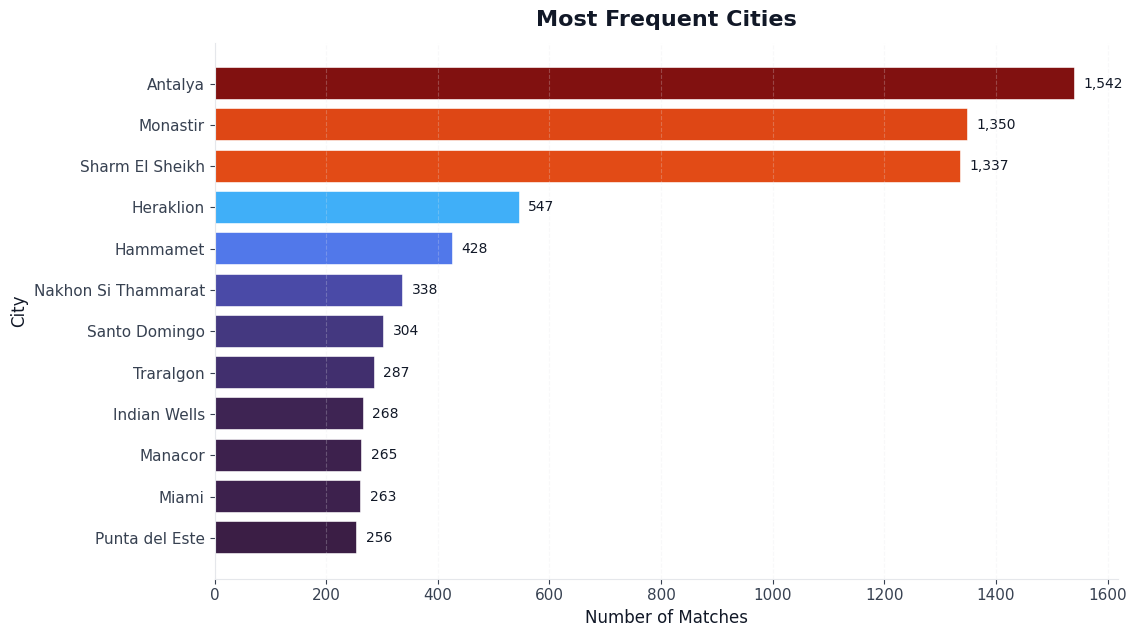


Top stadiums within top 6 cities:


,city,stadium,Matches
2,Antalya,Court 1,143
10,Antalya,Court 5,141
4,Antalya,Court 2,140
8,Antalya,Court 3,140
6,Antalya,Court 21,116
67,Hammamet,Court 1,68
70,Hammamet,Court 3,55
76,Hammamet,Court 9,48
75,Hammamet,Court 8,46
73,Hammamet,Court 6,43


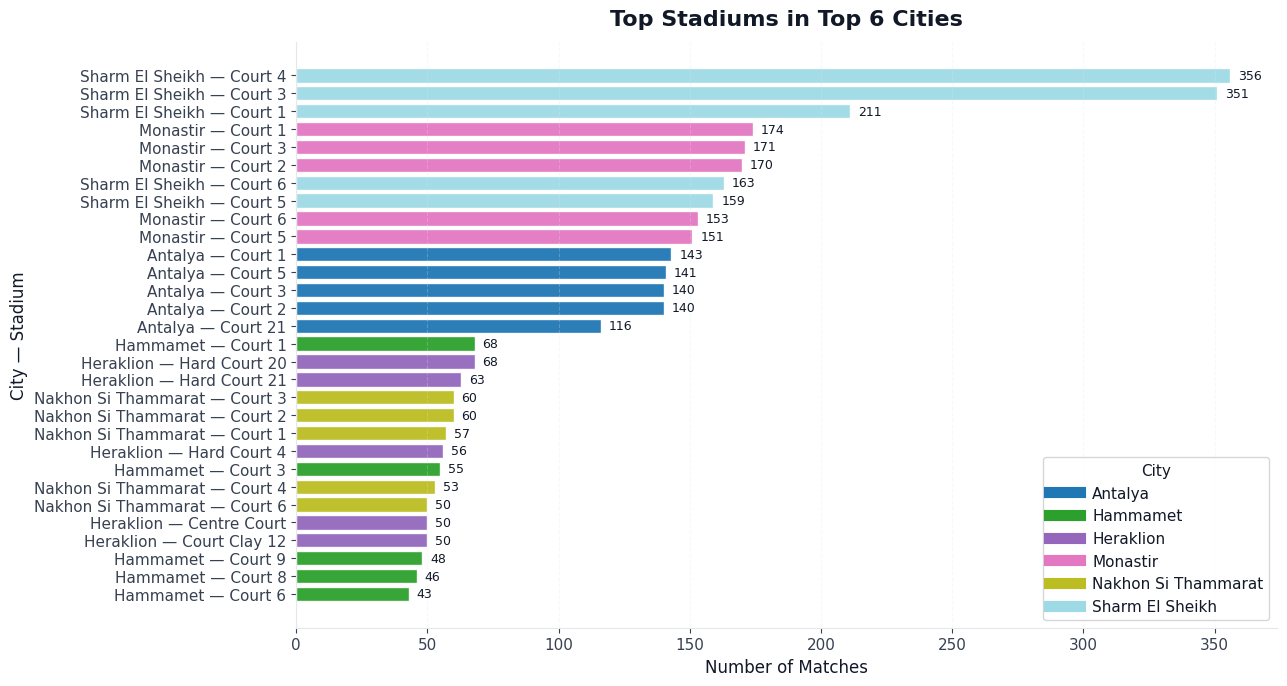

In [ ]:
if 'MatchVenueInfo' not in globals() or MatchVenueInfo is None:
    MatchVenueInfo_path, MatchVenueInfo = load_csv('MatchVenueInfo.csv')

# =========================
# Settings
# =========================
TOP_CITY_N = 12              
TOP_CITIES_FOR_STADIUM = 6   
TOP_STADIUM_PER_CITY = 5     

# =========================
# Clean & deduplicate (one row per match_id)
# =========================
venue = MatchVenueInfo.copy()

# Clean text columns
for col in ["city", "stadium", "country"]:
    if col in venue.columns:
        venue[col] = venue[col].fillna("Unknown").astype(str).str.strip()
        venue.loc[venue[col].eq(""), col] = "Unknown"

# manual deduplication based on match_id
venue = venue.drop_duplicates(subset=["match_id"])

# =========================
# 1) Top Cities by match count
# =========================
city_counts = venue["city"].value_counts()
top_cities = city_counts.head(TOP_CITY_N)

print("Top Cities by number of matches:")
display(top_cities.to_frame(name="Matches"))

# --- Plot: Top cities (colorful gradient) ---
vals = top_cities.values
labs = top_cities.index.astype(str).tolist()

# color mapping by value (gradient)
norm = plt.Normalize(vmin=min(vals), vmax=max(vals))
colors = plt.cm.turbo(norm(vals))  

fig, ax = plt.subplots(figsize=(11.5, 6.5), facecolor="white")
ax.set_facecolor("white")

bars = ax.barh(labs[::-1], vals[::-1], color=colors[::-1], edgecolor="white", linewidth=1.2, alpha=0.95)

ax.set_title("Most Frequent Cities", fontsize=16, fontweight="bold", pad=12)
ax.set_xlabel("Number of Matches")
ax.set_ylabel("City")

ax.grid(axis="x", linestyle="--", alpha=0.25)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# labels on bars
max_v = int(max(vals)) if len(vals) else 0
offset = max(1, int(max_v * 0.01)) if max_v else 1

for b in bars:
    v = int(b.get_width())
    ax.text(v + offset, b.get_y() + b.get_height()/2, f"{v:,}", va="center", ha="left", fontsize=10)

plt.tight_layout()
plt.show()

# =========================
# 2) Stadiums inside Top Cities
# =========================
focus_cities = city_counts.head(TOP_CITIES_FOR_STADIUM).index.tolist()
sub = venue[venue["city"].isin(focus_cities)].copy()

# match counts per (city, stadium)
city_stadium_counts = (
    sub.groupby(["city", "stadium"], as_index=False)["match_id"]
       .nunique()
       .rename(columns={"match_id": "Matches"})
)

# top stadiums per city
city_stadium_top = (
    city_stadium_counts.sort_values(["city", "Matches"], ascending=[True, False])
    .groupby("city", as_index=False)
    .head(TOP_STADIUM_PER_CITY)
)

# label format: City — Stadium
city_stadium_top["label"] = city_stadium_top["city"].astype(str) + " — " + city_stadium_top["stadium"].astype(str)

# sort by Matches ascending for horizontal bar chart
city_stadium_top = city_stadium_top.sort_values("Matches", ascending=True)

print(f"\nTop stadiums within top {TOP_CITIES_FOR_STADIUM} cities:")
display(city_stadium_top[["city", "stadium", "Matches"]].sort_values(["city", "Matches"], ascending=[True, False]))

# color per city (categorical)
unique_focus_cities = sorted(city_stadium_top["city"].unique().tolist())
palette = plt.cm.tab20(np.linspace(0, 1, max(3, len(unique_focus_cities))))
city_color = {c: palette[i] for i, c in enumerate(unique_focus_cities)}

bar_colors = city_stadium_top["city"].map(city_color).tolist()

fig, ax = plt.subplots(figsize=(13, 7), facecolor="white")
ax.set_facecolor("white")

bars = ax.barh(city_stadium_top["label"], city_stadium_top["Matches"],
               color=bar_colors, edgecolor="white", linewidth=1.0, alpha=0.95)

ax.set_title(f"Top Stadiums in Top {TOP_CITIES_FOR_STADIUM} Cities", fontsize=16, fontweight="bold", pad=12)
ax.set_xlabel("Number of Matches")
ax.set_ylabel("City — Stadium")

ax.grid(axis="x", linestyle="--", alpha=0.25)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

max_v2 = int(city_stadium_top["Matches"].max()) if len(city_stadium_top) else 0
offset2 = max(1, int(max_v2 * 0.01)) if max_v2 else 1

for b in bars:
    v = int(b.get_width())
    ax.text(v + offset2, b.get_y() + b.get_height()/2, f"{v:,}", va="center", ha="left", fontsize=9)

# Legend (city colors)
handles = [plt.Line2D([0], [0], color=city_color[c], lw=8) for c in unique_focus_cities]
ax.legend(handles, unique_focus_cities, title="City", loc="lower right", frameon=True)

plt.tight_layout()
plt.show()